In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

In [2]:
csc = 'Crimes-Sexuais_2009-a-2025_com_regiao.xlsx'#carregar os dados
df_raw = pd.read_excel(csc) #deixar o arquivo cru
df = df_raw.copy() #criar uma cópia

print('\n Linhas e Colunas')
print(df.shape)
print('\n Cabeçalho')
display(df.head())
print('\n Tipo de Dados')
print(df.info())
print('\n Estatística')
print(df.describe())


 Linhas e Colunas
(30772, 10)

 Cabeçalho


,AIS,Município,Região,Data,Hora,Dia da Semana,Gênero,Idade da Vítima,Escolaridade da Vítima,Raça da Vítima
0,AIS 25,Itaitinga,Grande Fortaleza,2009-01-01,01:30:00,Quinta,Feminino,13,Não Informada,Não Informada
1,AIS 30,Aracati,Litoral Leste,2009-01-01,20:30:00,Quinta,Feminino,41,Não Informada,Não Informada
2,AIS 06,Fortaleza,Grande Fortaleza,2009-01-02,11:06:06,Sexta,Masculino,16,Não Informada,Não Informada
3,AIS Não Identificada (Caucaia),Caucaia,Grande Fortaleza,2009-01-02,12:13:09,Sexta,Feminino,13,Não Informada,Não Informada
4,AIS 20,Fortaleza,Grande Fortaleza,2009-01-02,21:04:52,Sexta,Feminino,13,Não Informada,Não Informada



 Tipo de Dados
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30772 entries, 0 to 30771
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   AIS                     30772 non-null  object        
 1   Município               30772 non-null  object        
 2   Região                  30772 non-null  object        
 3   Data                    30772 non-null  datetime64[ns]
 4   Hora                    30772 non-null  object        
 5   Dia da Semana           30772 non-null  object        
 6   Gênero                  30772 non-null  object        
 7   Idade da Vítima         30772 non-null  object        
 8   Escolaridade da Vítima  30772 non-null  object        
 9   Raça da Vítima          30772 non-null  object        
dtypes: datetime64[ns](1), object(9)
memory usage: 2.3+ MB
None

 Estatística
                                Data
count                          30772
mea

1 Evolução Temporal

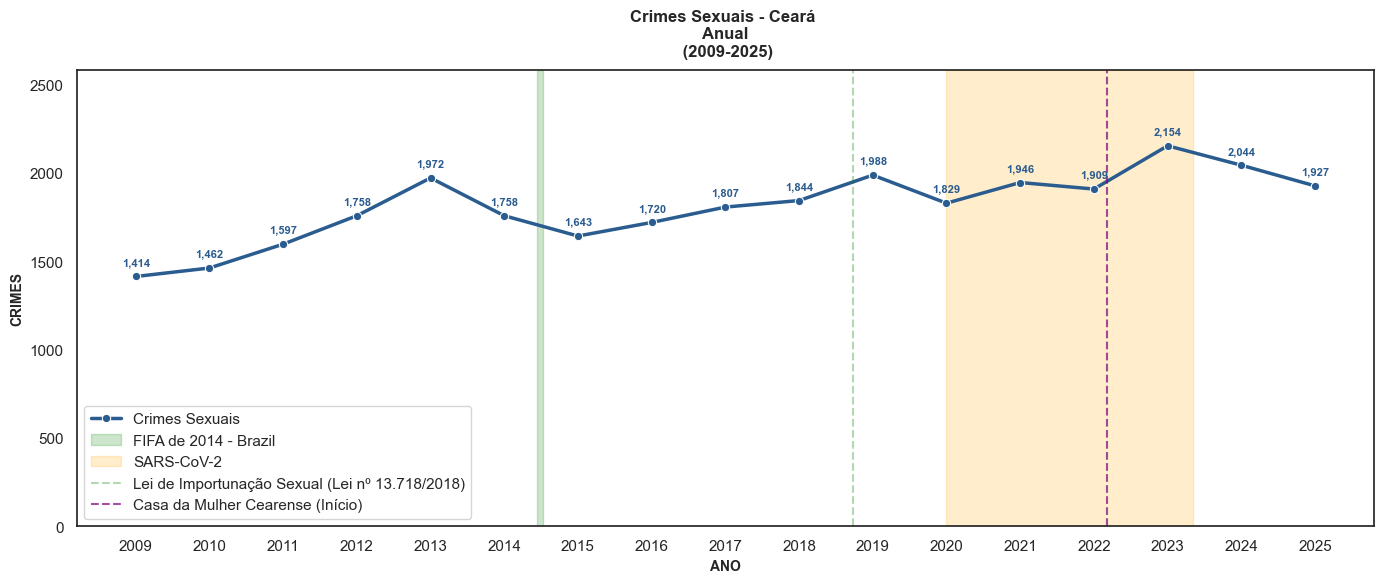

In [233]:
df['Data'] = pd.to_datetime(df['Data'], format='%d/%m/%Y')
df['ANO'] = df['Data'].dt.year
tabela_anos = df.groupby('ANO').size().reset_index(name='CRIMES')
tabela_anos.columns = ['ANO', 'CRIMES']

# 2. Plotar gráfico de linha com a evolução temporal e marcos históricos
plt.figure(figsize=(14, 6))

sns.set_theme(
    context='notebook', 
    style='white', 
    palette='deep', 
    font='sans-serif', 
    font_scale=1, 
    color_codes=True, rc=None)

#linha azul
grafico_anos = sns.lineplot(
    x='ANO',
    y='CRIMES',
    data=tabela_anos,
    marker='o',
    color='#2b5c8f',
    linewidth=2.5,
    label='Crimes Sexuais'
)

# Adicionar os valores exatos em cada ponto do gráfico
for i in range(len(tabela_anos)):
    plt.text(
        tabela_anos['ANO'][i],
        tabela_anos['CRIMES'][i] + (tabela_anos['CRIMES'].max() * 0.025),
        f"{tabela_anos['CRIMES'][i]:,}",
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold',
        color='#2b5c8f'
    )

# Copa do mundo
plt.axvspan(
    xmin=2014.44, 
    xmax=2014.53, 
    color='green', 
    alpha=0.2, 
    label='FIFA de 2014 - Brazil'
    )

# Marco 1: Faixa da Pandemia (2020-21)
plt.axvspan(
    xmin=2019.99, 
    xmax=2023.34, 
    color='orange', 
    alpha=0.2, 
    label='SARS-CoV-2'
    )

# Marco 2: Lei de Importunação Sexual (2018)
plt.axvline(
    x=2018.73, 
    color='green', 
    linestyle='--', 
    alpha=0.3,
    label='Lei de Importunação Sexual (Lei nº 13.718/2018)'
    )

# Marco 3: Início da expansão da Casa da Mulher Cearense (fim de 2021/2022)
plt.axvline(
    x=2022.18, 
    color='purple', 
    linestyle='--', 
    alpha=0.7,
    label='Casa da Mulher Cearense (Início)'
    )

# Título do gráfico
plt.title(
    label='Crimes Sexuais - Ceará \n Anual \n (2009-2025)', 
    fontsize=12, 
    fontweight='bold', 
    pad=10
    )

plt.xlabel('ANO', fontsize=10, fontweight='bold')
plt.ylabel('CRIMES', fontsize=10, fontweight='bold')
plt.xticks(tabela_anos['ANO'])
plt.ylim(0, tabela_anos['CRIMES'].max() * 1.2)
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()

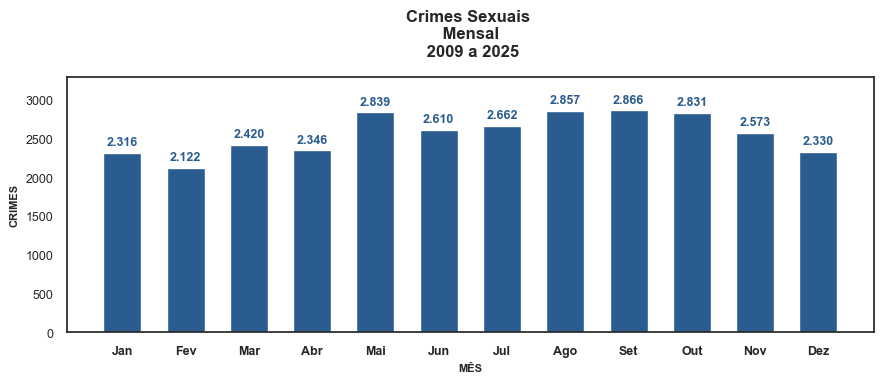

In [247]:
# 1. Garante as colunas de ano e mês
df['ANO'] = df['Data'].dt.year
df['MES'] = df['Data'].dt.month

# 2. Agrupa apenas por MÊS e soma todos os registros do período de 2009 a 2025
tabela_meses = df.groupby('MES').size().reset_index(name='TOTAL_CRIMES')

# Cria uma lista com os nomes dos meses para facilitar a visualização
nomes_meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
tabela_meses['NOME_MES'] = nomes_meses

# 3. Plota o gráfico de barras com a quantidade absoluta total
plt.figure(figsize=(9, 4))

barras = plt.bar(
    tabela_meses['NOME_MES'], 
    tabela_meses['TOTAL_CRIMES'], 
    color='#2b5c8f', 
    width=0.6
)

# Adiciona o valor absoluto exato em cima de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2.,
        altura + (tabela_meses['TOTAL_CRIMES'].max() * 0.02),
        f"{int(altura):,}".replace(",", "."),  # Formata com separador de milhar brasileiro (ex: 1.250)
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color='#2b5c8f'
    )

# Títulos e formatações
plt.title('Crimes Sexuais \n Mensal \n 2009 a 2025', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('MÊS', fontsize=8, fontweight='bold')
plt.ylabel('CRIMES', fontsize=8, fontweight='bold')
plt.xticks(fontsize=9, fontweight='bold')
plt.yticks(fontsize=9)

# Dá uma margem extra no topo para o texto não cortar
plt.ylim(0, tabela_meses['TOTAL_CRIMES'].max() * 1.15)

plt.tight_layout()
plt.show()

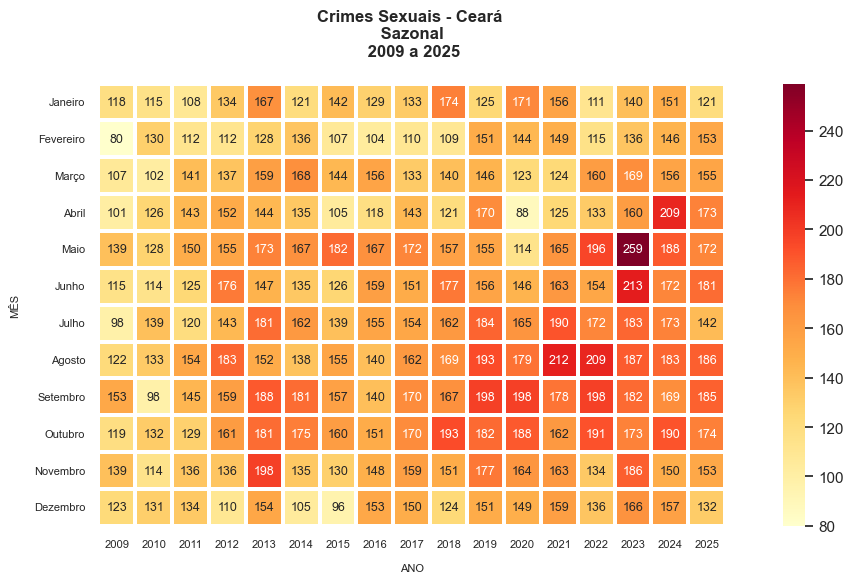

In [235]:
# 1. Agrupar os dados por ANO e MES
dados_heatmap = df.groupby(['ANO', 'MES']).size().reset_index(name='CRIMES')

# 2. Pivotar colocando MES no índice (Eixo Y) e ANO nas colunas (Eixo X)
matriz_quadradinhos = dados_heatmap.pivot(index='MES', columns='ANO', values='CRIMES').fillna(0)

# Mapear os meses para o formato em português
meses_pt = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril', 5: 'Maio', 6: 'Junho',
    7: 'Julho', 8: 'Agosto', 9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}
matriz_quadradinhos.index = matriz_quadradinhos.index.map(meses_pt)

# 3. Gerar o gráfico com células bem marcadas (quadradinhos)
plt.figure(figsize=(12, 6))

# Desenhando o heatmap com linhas de divisão para destacar os quadradinhos
sns.heatmap(
    matriz_quadradinhos,
    fmt='g',             # Formato inteiro geral
    annot=True,
    cmap='YlOrRd',       # Paleta de cores do amarelo ao vermelho
    linewidths=1.5,      # Espessura das linhas divisórias para formar os quadradinhos
    linecolor='white',   # Cor das divisões dos quadradinhos
    square=True,         # Força cada célula do heatmap a ser um quadrado perfeito
    annot_kws={"size": 9}
)

plt.title('Crimes Sexuais - Ceará \n Sazonal \n 2009 a 2025', fontsize=12, fontweight='bold', pad=20)
plt.xlabel('ANO', fontsize=8, labelpad=10)
plt.ylabel('MÊS', fontsize=8, labelpad=10)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8, rotation=0) # Mantém os meses na horizontal para facilitar a leitura
plt.tight_layout()
plt.show()

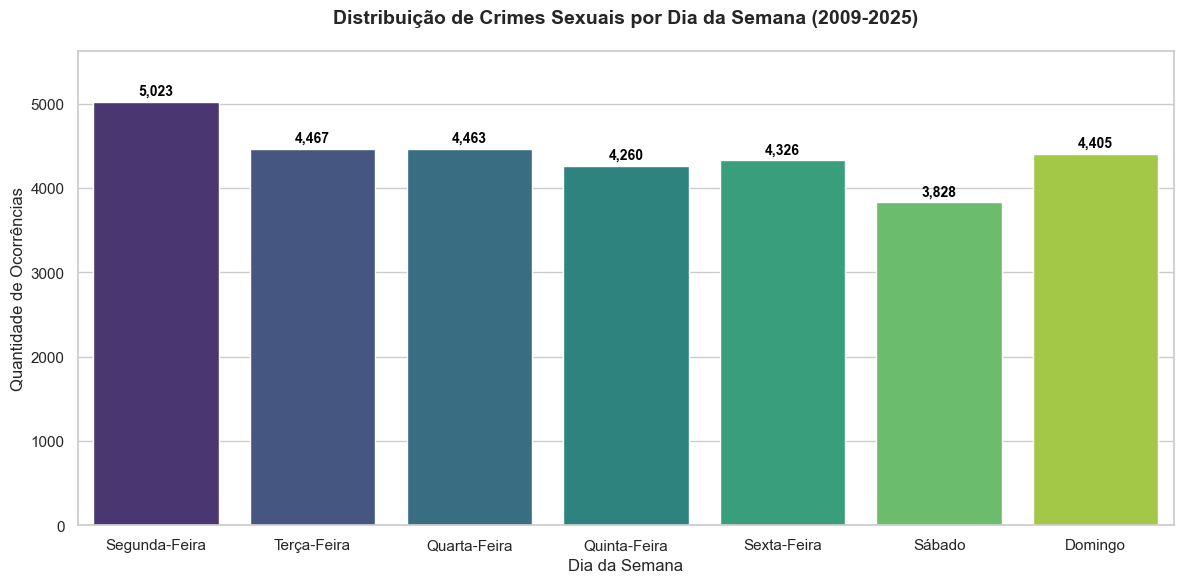

In [253]:
# 1. Agrupar e contar as ocorrências por dia da semana
tabela_dias = df['Dia da Semana'].value_counts().reset_index()
tabela_dias.columns = ['Dia da Semana', 'Quantidade']

# Limpar strings e converter para minúsculas para padronizar independentemente de acentos ou hífens
tabela_dias['Dia_Semana_Limpo'] = tabela_dias['Dia da Semana'].astype(str).str.strip().str.lower()

# Criar um mapeamento seguro para normalizar os dias encontrados nos dados do Ceará
mapeamento_dias = {
    'segunda-feira': 'Segunda-Feira', 'segunda feira': 'Segunda-Feira', 'segunda': 'Segunda-Feira',
    'terça-feira': 'Terça-Feira', 'terça feira': 'Terça-Feira', 'terca-feira': 'Terça-Feira', 'terça': 'Terça-Feira',
    'quarta-feira': 'Quarta-Feira', 'quarta feira': 'Quarta-Feira', 'quarta': 'Quarta-Feira',
    'quinta-feira': 'Quinta-Feira', 'quinta feira': 'Quinta-Feira', 'quinta': 'Quinta-Feira',
    'sexta-feira': 'Sexta-Feira', 'sexta feira': 'Sexta-Feira', 'sexta': 'Sexta-Feira',
    'sábado': 'Sábado', 'sabado': 'Sábado',
    'domingo': 'Domingo'
}

# Aplicar o mapeamento
tabela_dias['Dia da Semana Formatado'] = tabela_dias['Dia_Semana_Limpo'].map(mapeamento_dias)

# Consolidar quantidades em caso de duplicidades causadas por grafias diferentes
tabela_dias = tabela_dias.groupby('Dia da Semana Formatado')['Quantidade'].sum().reset_index()
tabela_dias.columns = ['Dia da Semana', 'Quantidade']

# Definir a ordem cronológica correta
ordem_dias = [
    'Segunda-Feira',
    'Terça-Feira',
    'Quarta-Feira',
    'Quinta-Feira',
    'Sexta-Feira',
    'Sábado',
    'Domingo'
]

# Reordenar o DataFrame
tabela_dias['Dia da Semana'] = pd.Categorical(tabela_dias['Dia da Semana'], categories=ordem_dias, ordered=True)
tabela_dias = tabela_dias.sort_values('Dia da Semana').reset_index(drop=True)

# 2. Plotar o gráfico
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

grafico_dias = sns.barplot(
    x='Dia da Semana',
    y='Quantidade',
    data=tabela_dias,
    palette='viridis'
)

# Adicionar os valores exatos em cima de cada barra
for p in grafico_dias.patches:
    alt = p.get_height()
    if not np.isnan(alt):
        grafico_dias.annotate(
            f"{int(alt):,}",
            (p.get_x() + p.get_width() / 2., alt),
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold',
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.title('Distribuição de Crimes Sexuais por Dia da Semana (2009-2025)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Dia da Semana', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.ylim(0, tabela_dias['Quantidade'].max() * 1.12)

plt.tight_layout()
plt.show()

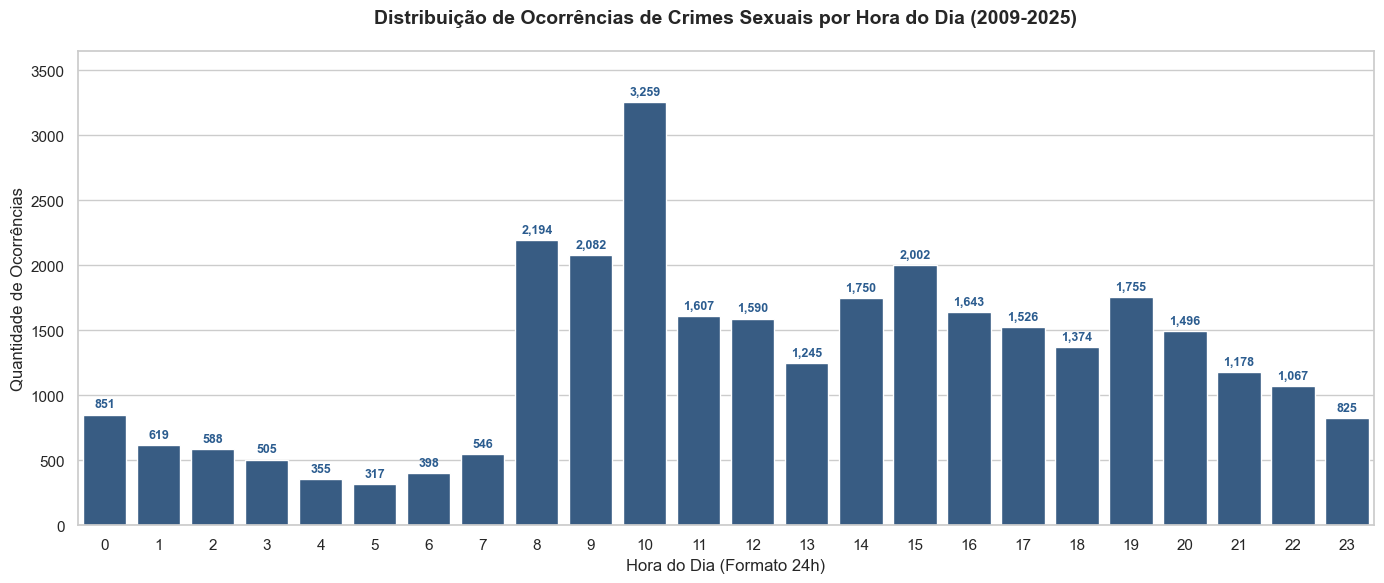

In [252]:
# 1. Limpeza e extração da hora cheia
# Vamos garantir que os valores sejam strings e extrair os primeiros 2 dígitos (que representam a hora)
df['Hora_Limpa'] = df['Hora'].astype(str).str.strip().str[:2]

# Filtrar apenas valores numéricos válidos (de 00 a 23)
df_horas = df[df['Hora_Limpa'].str.isnumeric()]
df_horas['Hora_Inteira'] = df_horas['Hora_Limpa'].astype(int)
df_horas = df_horas[(df_horas['Hora_Inteira'] >= 0) & (df_horas['Hora_Inteira'] <= 23)]

# Agrupar e contar por hora
tabela_horas = df_horas['Hora_Inteira'].value_counts().reset_index()
tabela_horas.columns = ['Hora', 'Quantidade']
tabela_horas = tabela_horas.sort_values('Hora').reset_index(drop=True)

# 2. Plotar gráfico de distribuição por hora
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Criar gráfico de barras
grafico_horas = sns.barplot(
    x='Hora',
    y='Quantidade',
    data=tabela_horas,
    color='#2b5c8f'
)

# Adicionar os valores exatos no topo de cada barra
for p in grafico_horas.patches:
    grafico_horas.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color='#2b5c8f',
        xytext=(0, 3),
        textcoords='offset points'
    )

plt.title('Distribuição de Ocorrências de Crimes Sexuais por Hora do Dia (2009-2025)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Hora do Dia (Formato 24h)', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.xticks(range(24))
plt.ylim(0, tabela_horas['Quantidade'].max() * 1.12)

plt.tight_layout()
plt.show()

Dimensão 2 — Distribuição geográfica

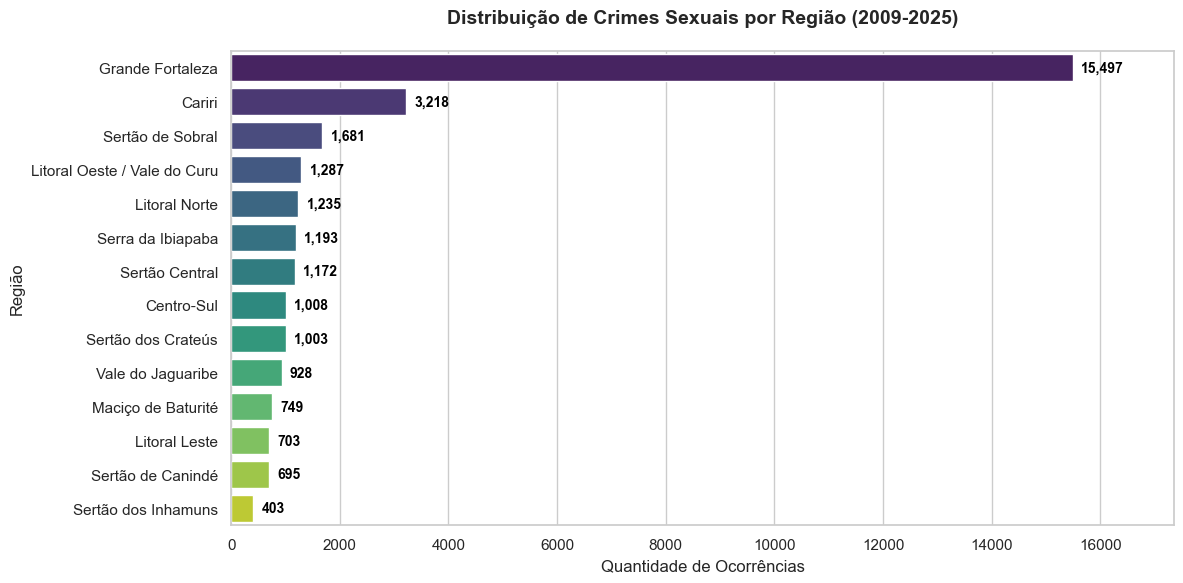

In [255]:
# 1. Agrupar e contar as ocorrências por Região
tabela_regioes = df['Região'].value_counts().reset_index()
tabela_regioes.columns = ['Região', 'Quantidade']
tabela_regioes = tabela_regioes.sort_values('Quantidade', ascending=False).reset_index(drop=True)

# 2. Plotar o gráfico
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

grafico_regioes = sns.barplot(
    x='Quantidade',
    y='Região',
    data=tabela_regioes,
    palette='viridis'
)

# Adicionar os valores exatos ao lado de cada barra
for i, v in enumerate(tabela_regioes['Quantidade']):
    plt.text(
        v + (tabela_regioes['Quantidade'].max() * 0.01),
        i,
        f"{int(v):,}",
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='black'
    )

plt.title('Distribuição de Crimes Sexuais por Região (2009-2025)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Quantidade de Ocorrências', fontsize=12)
plt.ylabel('Região', fontsize=12)
plt.xlim(0, tabela_regioes['Quantidade'].max() * 1.12)

plt.tight_layout()
plt.show()

,Município,Quantidade
0,Fortaleza,9881
1,Juazeiro do Norte,884
2,Crato,449
3,Quixadá,272
4,Barbalha,222
5,Baturité,126
6,Aracoiaba,102


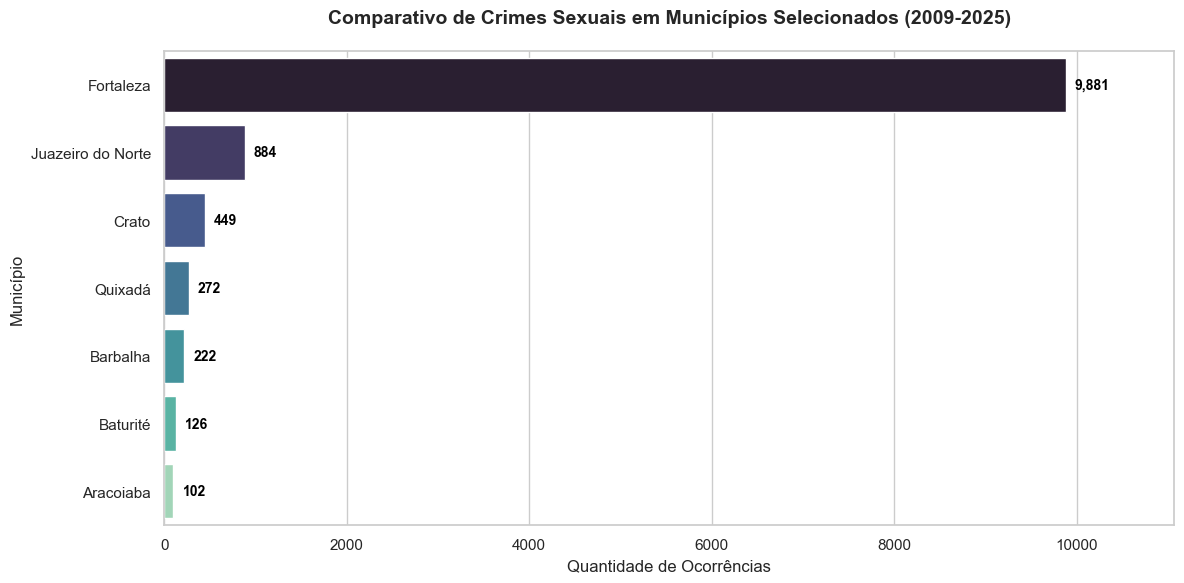

In [256]:
# 1. Lista de municípios especificada pelo usuário
municipios_alvo = [
    'Fortaleza', 'Aracoiaba', 'Baturité', 'Quixadá', 
    'Juazeiro do Norte', 'Barbalha', 'Crato'
]

# Padronizar a coluna Município para garantir que a busca funcione sem problemas de maiúsculas/minúsculas
df['Município_Limpo'] = df['Município'].astype(str).str.strip()

# Filtrar o DataFrame apenas com os municípios escolhidos
df_filtrado = df[df['Município_Limpo'].isin(municipios_alvo)]

# Agrupar e contar as ocorrências por município
tabela_municipios = df_filtrado['Município_Limpo'].value_counts().reset_index()
tabela_municipios.columns = ['Município', 'Quantidade']

# Garantir que todos os municípios da lista apareçam na tabela (mesmo se tivessem 0 casos)
tabela_municipios = tabela_municipios.set_index('Município').reindex(municipios_alvo, fill_value=0).reset_index()
tabela_municipios = tabela_municipios.sort_values('Quantidade', ascending=False).reset_index(drop=True)

# Exibir tabela no notebook
display(tabela_municipios)

# 2. Plotar o gráfico comparativo
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

grafico_muns = sns.barplot(
    x='Quantidade',
    y='Município',
    data=tabela_municipios,
    palette='mako'
)

# Adicionar valores ao lado de cada barra
for i, v in enumerate(tabela_municipios['Quantidade']):
    plt.text(
        v + (tabela_municipios['Quantidade'].max() * 0.01),
        i,
        f"{int(v):,}",
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='black'
    )

plt.title('Comparativo de Crimes Sexuais em Municípios Selecionados (2009-2025)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Quantidade de Ocorrências', fontsize=12)
plt.ylabel('Município', fontsize=12)
plt.xlim(0, tabela_municipios['Quantidade'].max() * 1.12)

plt.tight_layout()
plt.show()

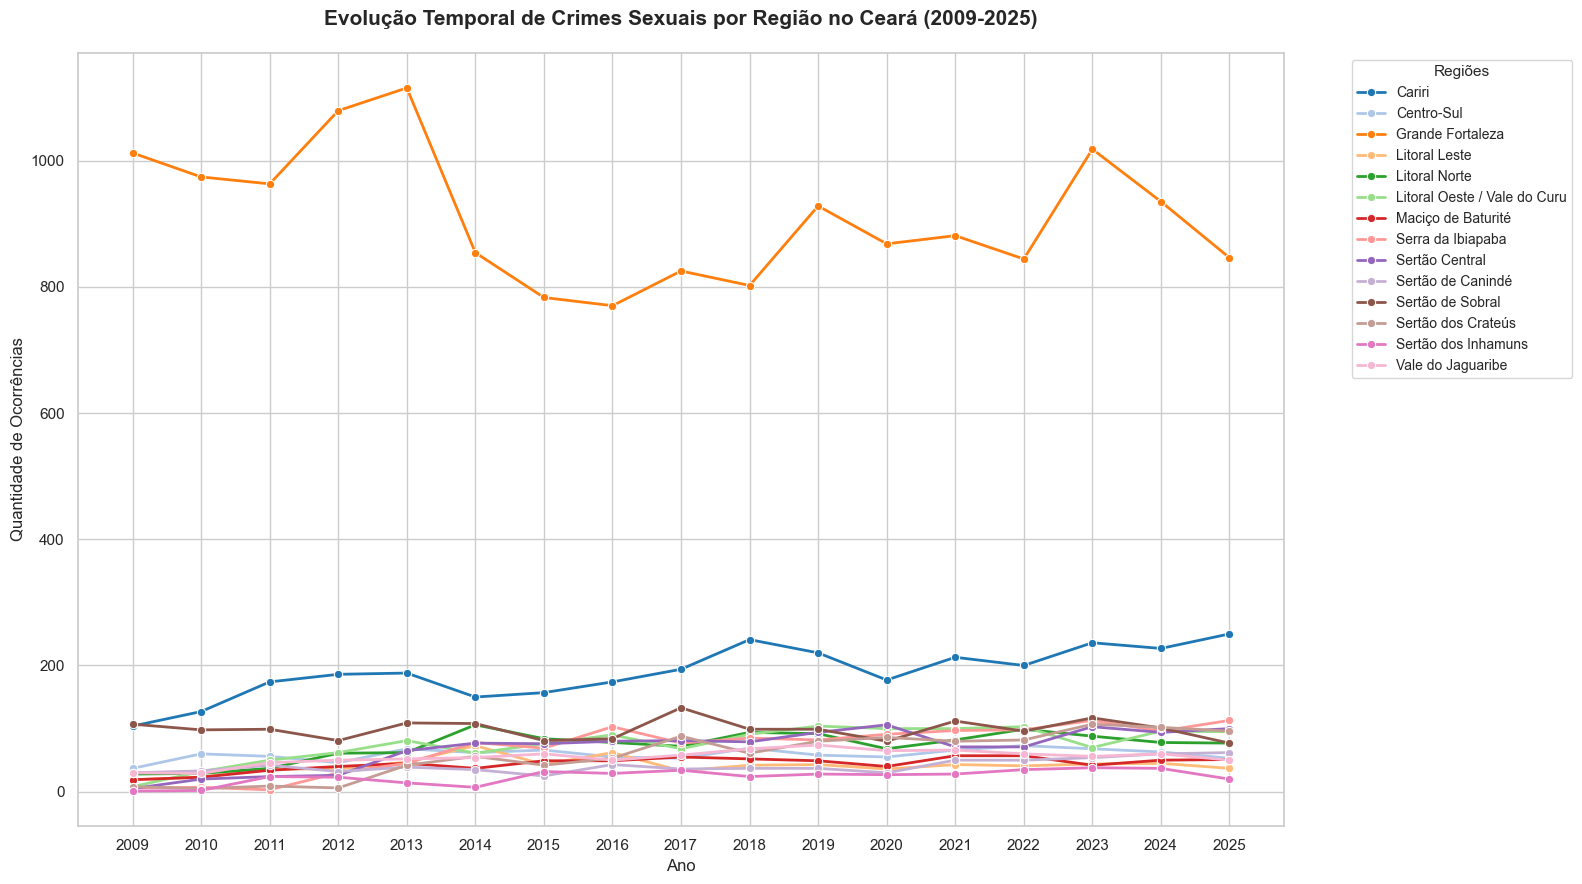

In [257]:
# 1. Garantir que a coluna 'Ano' existe e agrupar os dados por Ano e Região
df['Ano'] = df['Data'].dt.year
tabela_regiao_ano = df.groupby(['Ano', 'Região']).size().reset_index(name='Quantidade')

# 2. Plotar o gráfico de linhas por Ano e Região
plt.figure(figsize=(16, 9))
sns.set_theme(style="whitegrid")

# Usar uma paleta de cores variada e bem visível para diferenciar as 14 regiões
grafico_evolucao_regional = sns.lineplot(
    x='Ano',
    y='Quantidade',
    hue='Região',
    data=tabela_regiao_ano,
    marker='o',
    linewidth=2,
    palette='tab20'
)

plt.title('Evolução Temporal de Crimes Sexuais por Região no Ceará (2009-2025)', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.xticks(tabela_regiao_ano['Ano'].unique())

# Posicionar a legenda fora do gráfico para não obstruir as linhas
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Regiões', fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.show()

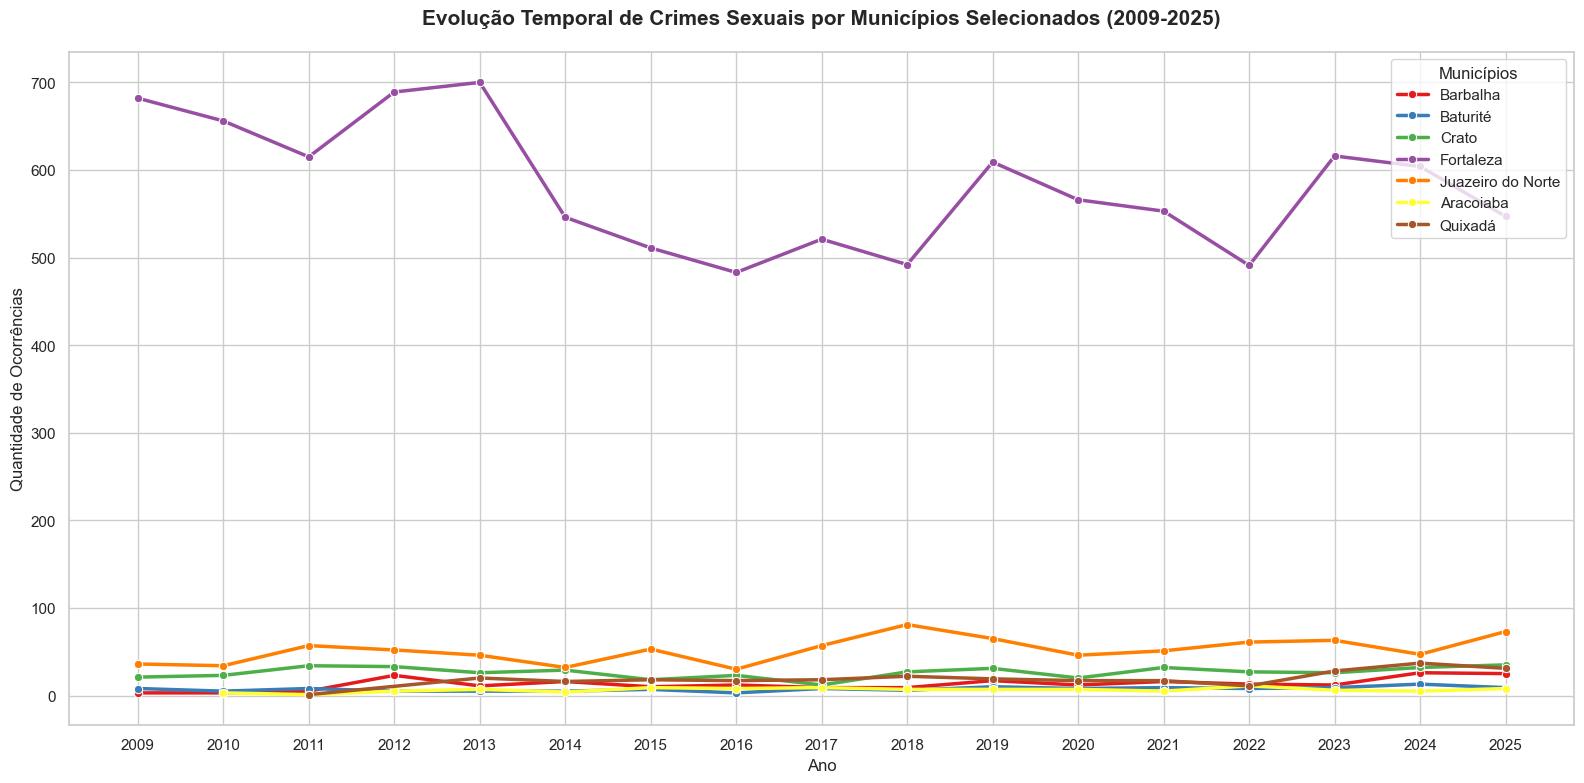

In [258]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar os dados do DataFrame filtrado por Ano e Município
df_filtrado['Ano'] = df_filtrado['Data'].dt.year
tabela_mun_ano = df_filtrado.groupby(['Ano', 'Município_Limpo']).size().reset_index(name='Quantidade')

# 2. Plotar o gráfico de linhas com a evolução temporal de cada município selecionado
plt.figure(figsize=(16, 8))
sns.set_theme(style="whitegrid")

# Plotando as séries temporais
grafico_evolucao_mun = sns.lineplot(
    x='Ano',
    y='Quantidade',
    hue='Município_Limpo',
    data=tabela_mun_ano,
    marker='o',
    linewidth=2.5,
    palette='Set1'
)

plt.title('Evolução Temporal de Crimes Sexuais por Municípios Selecionados (2009-2025)', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.xticks(tabela_mun_ano['Ano'].unique())

# Ajustar a legenda para melhor visualização
plt.legend(title='Municípios', loc='upper right', fontsize=11, title_fontsize=12)

plt.tight_layout()
plt.show()

Dimensão 3 — Perfil demográfico

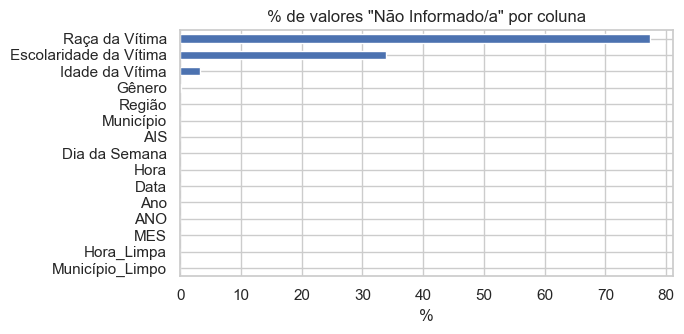

In [259]:
nao_inf = df.apply(lambda s: s.astype(str).str.startswith('Não Informad').mean()).sort_values(ascending=False)
ax = (nao_inf*100).plot.barh(figsize=(7,3.5), color='#4C72B0')
ax.set_title('% de valores "Não Informado/a" por coluna'); ax.set_xlabel('%')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

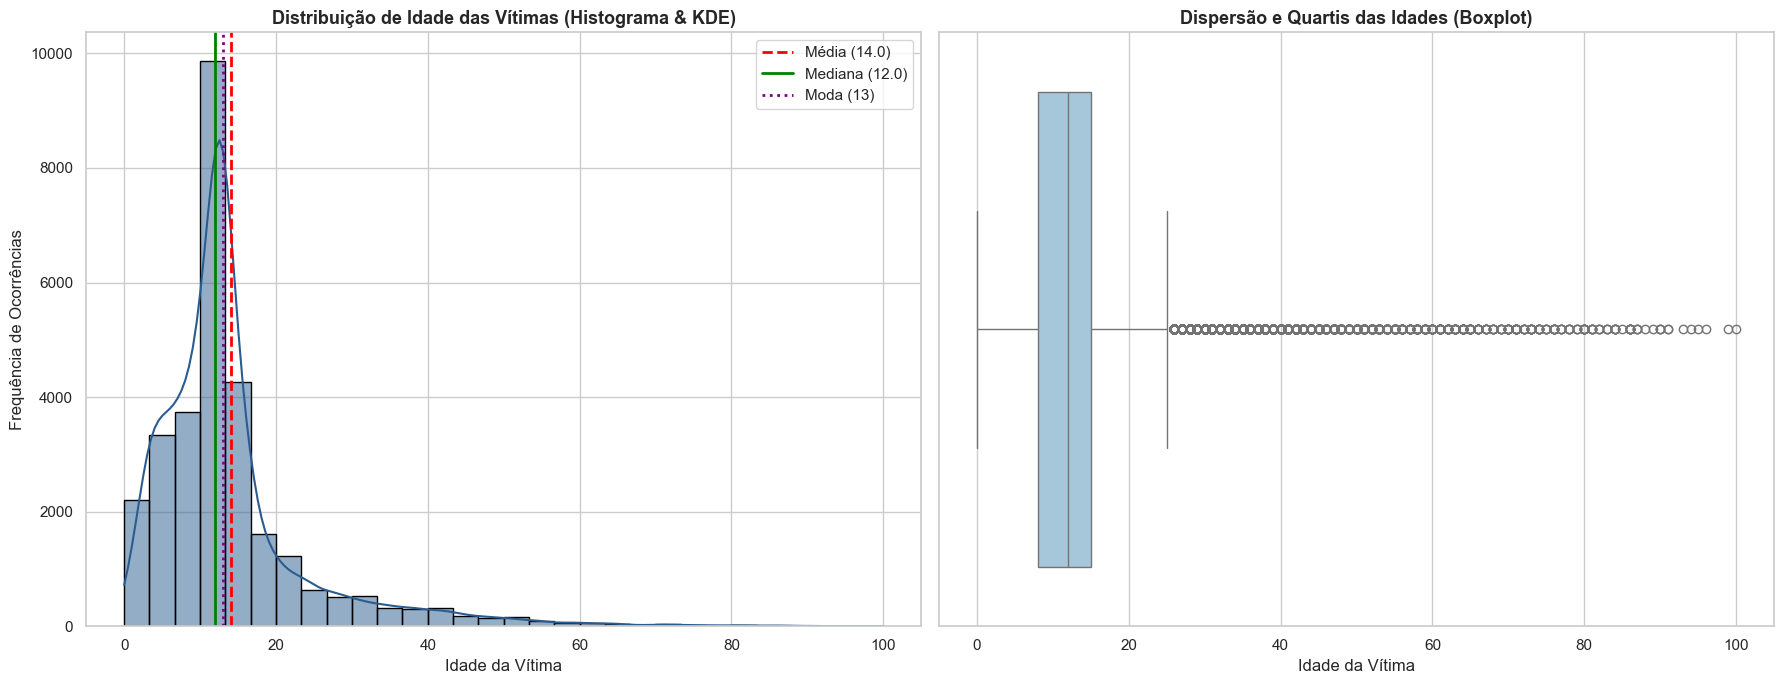

In [262]:
# 3. Criar a visualização gráfica (Histograma com KDE e Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.set_theme(style="whitegrid")

# Histograma com Curva KDE
sns.histplot(
    data=df_idade_valida,
    x='Idade_Limpa',
    kde=True,
    ax=axes[0],
    color='#2b5c8f',
    bins=30,
    edgecolor='black'
)
axes[0].axvline(media_idade, color='red', linestyle='--', linewidth=2, label=f'Média ({media_idade:.1f})')
axes[0].axvline(mediana_idade, color='green', linestyle='-', linewidth=2, label=f'Mediana ({mediana_idade:.1f})')
axes[0].axvline(moda_idade, color='purple', linestyle=':', linewidth=2, label=f'Moda ({moda_idade})')
axes[0].set_title('Distribuição de Idade das Vítimas (Histograma & KDE)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Idade da Vítima')
axes[0].set_ylabel('Frequência de Ocorrências')
axes[0].legend()

# Boxplot para detecção de Outliers e dispersão
sns.boxplot(
    data=df_idade_valida,
    x='Idade_Limpa',
    ax=axes[1],
    color='#9ecae1',
    orient='h'
)
axes[1].set_title('Dispersão e Quartis das Idades (Boxplot)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Idade da Vítima')

plt.tight_layout()
plt.show()

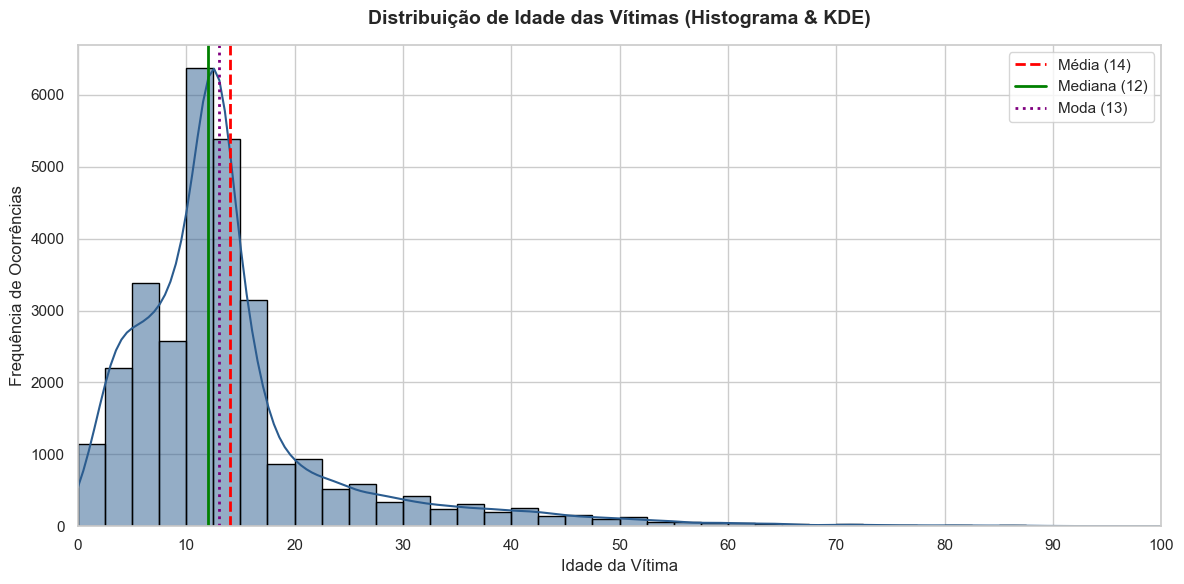

In [273]:
# 3. Criar a visualização gráfica (Apenas Histograma com KDE - Limites de 0 a 100 anos)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Histograma com Curva KDE isolado
sns.histplot(
    data=df_idade_valida,
    x='Idade_Limpa',
    kde=True,
    color='#2b5c8f',
    bins=40, 
    edgecolor='black'
)

# Adicionar as linhas verticais para as principais métricas sem a casa decimal ".0" ou decimais adicionais
plt.axvline(media_idade, color='red', linestyle='--', linewidth=2, label=f'Média ({int(round(media_idade))})')
plt.axvline(mediana_idade, color='green', linestyle='-', linewidth=2, label=f'Mediana ({int(mediana_idade)})')
plt.axvline(moda_idade, color='purple', linestyle=':', linewidth=2, label=f'Moda ({int(moda_idade)})')

plt.title('Distribuição de Idade das Vítimas (Histograma & KDE)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Idade da Vítima', fontsize=12)
plt.ylabel('Frequência de Ocorrências', fontsize=12)
plt.xlim(0, 100)
plt.xticks(range(0, 101, 10))
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

=== ESTATÍSTICAS DESCRITIVAS DA IDADE ===
Total de registros com idade válida: 29757 (96.70% da base total)
Média: 14.01 anos
Mediana (Q2): 12.0 anos
Moda: 13 anos
Primeiro Quartil (Q1 - 25%): 8.0 anos
Terceiro Quartil (Q3 - 75%): 15.0 anos
Intervalo Interquartil (IQR): 7.0 anos


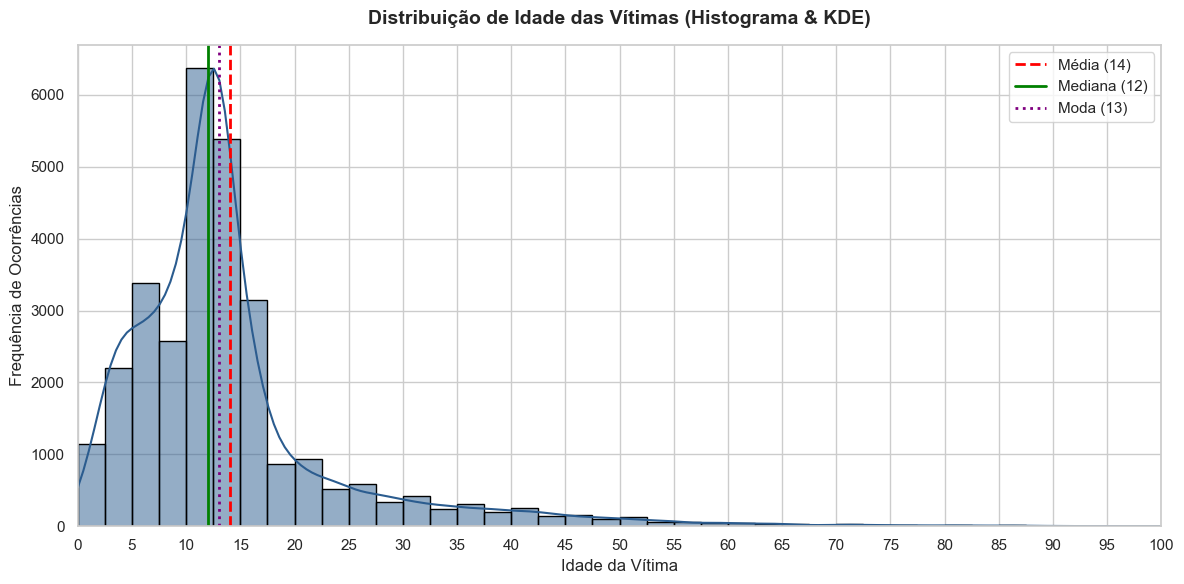

In [277]:
# 1. Limpeza e Tratamento da Coluna 'Idade da Vítima'
# Vamos verificar a presença de strings, valores nulos ou inválidos
df['Idade_Limpa'] = pd.to_numeric(df['Idade da Vítima'], errors='coerce')

# Filtrar idades plausíveis (0 a 110 anos), descartando ruídos como 999 ou inconsistências negativas
df_idade_valida = df[df['Idade_Limpa'].notnull()]
df_idade_valida = df_idade_valida[(df_idade_valida['Idade_Limpa'] >= 0) & (df_idade_valida['Idade_Limpa'] <= 110)]

# Converter para inteiro
df_idade_valida['Idade_Limpa'] = df_idade_valida['Idade_Limpa'].astype(int)

# 2. Cálculo das Métricas Estatísticas Descritivas
media_idade = df_idade_valida['Idade_Limpa'].mean()
mediana_idade = df_idade_valida['Idade_Limpa'].median()
moda_idade = df_idade_valida['Idade_Limpa'].mode()[0]
q1 = df_idade_valida['Idade_Limpa'].quantile(0.25)
q3 = df_idade_valida['Idade_Limpa'].quantile(0.75)
iqr = q3 - q1

print("=== ESTATÍSTICAS DESCRITIVAS DA IDADE ===")
print(f"Total de registros com idade válida: {len(df_idade_valida)} ({len(df_idade_valida)/len(df)*100:.2f}% da base total)")
print(f"Média: {media_idade:.2f} anos")
print(f"Mediana (Q2): {mediana_idade:.1f} anos")
print(f"Moda: {moda_idade} anos")
print(f"Primeiro Quartil (Q1 - 25%): {q1:.1f} anos")
print(f"Terceiro Quartil (Q3 - 75%): {q3:.1f} anos")
print(f"Intervalo Interquartil (IQR): {iqr:.1f} anos")

# 3. Criar a visualização gráfica (Apenas Histograma com KDE - Limites de 0 a 100 anos)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Histograma com Curva KDE isolado
sns.histplot(
    data=df_idade_valida,
    x='Idade_Limpa',
    kde=True,
    color='#2b5c8f',
    bins=40, 
    edgecolor='black'
)

# Adicionar as linhas verticais para as principais métricas
plt.axvline(media_idade, color='red', linestyle='--', linewidth=2, label=f'Média ({int(round(media_idade))})')
plt.axvline(mediana_idade, color='green', linestyle='-', linewidth=2, label=f'Mediana ({int(mediana_idade)})')
plt.axvline(moda_idade, color='purple', linestyle=':', linewidth=2, label=f'Moda ({int(moda_idade)})')

plt.title('Distribuição de Idade das Vítimas (Histograma & KDE)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Idade da Vítima', fontsize=12)
plt.ylabel('Frequência de Ocorrências', fontsize=12)
plt.xlim(0, 100) # Ajustado o limite do eixo X de 0 a 100 anos conforme solicitado
plt.xticks(range(0, 101, 5))
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

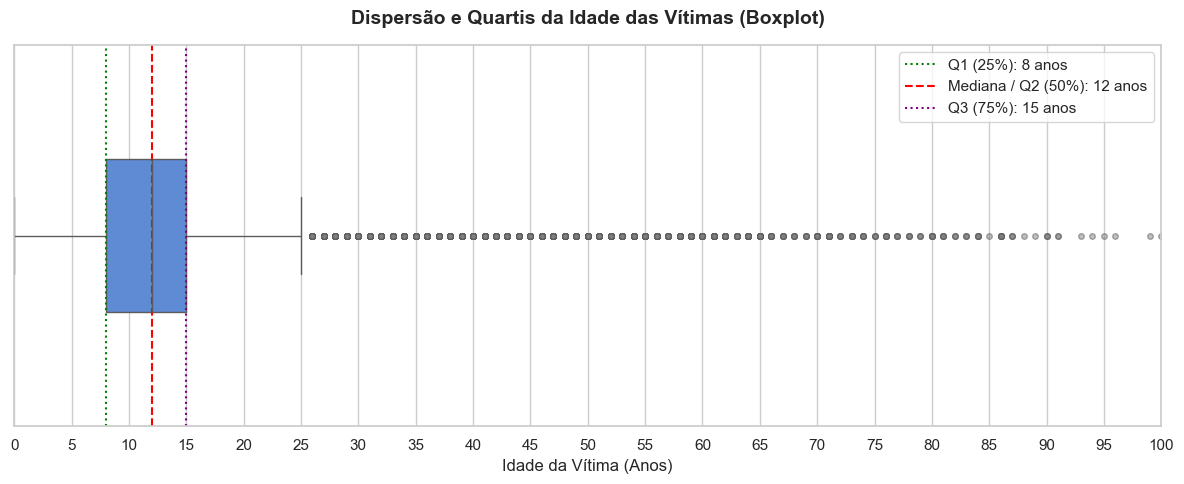

In [281]:
# Criar a visualização em quartis usando Boxplot (Gráfico de Caixa)
plt.figure(figsize=(12, 5))
sns.set_theme(style="whitegrid")

# Criando o boxplot horizontal
box_plot = sns.boxplot(
    x='Idade_Limpa',
    data=df_idade_valida,
    color='#4a86e8',
    width=0.4,
    flierprops=dict(marker='o', markerfacecolor='gray', markersize=4, linestyle='none', alpha=0.5)
)

# Destacar os valores dos quartis calculados anteriormente
plt.axvline(q1, color='green', linestyle=':', linewidth=1.5, label=f'Q1 (25%): {int(q1)} anos')
plt.axvline(mediana_idade, color='red', linestyle='--', linewidth=1.5, label=f'Mediana / Q2 (50%): {int(mediana_idade)} anos')
plt.axvline(q3, color='purple', linestyle=':', linewidth=1.5, label=f'Q3 (75%): {int(q3)} anos')

# Customizações estéticas
plt.title('Dispersão e Quartis da Idade das Vítimas (Boxplot)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Idade da Vítima (Anos)', fontsize=12)
plt.xlim(0, 100)
plt.xticks(range(0, 101, 5))
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

In [265]:
# 1. Limpeza e Tratamento da Coluna 'Idade da Vítima'
# Vamos verificar a presença de strings, valores nulos ou inválidos
df['Idade_Limpa'] = pd.to_numeric(df['Idade da Vítima'], errors='coerce')

# Filtrar idades plausíveis (0 a 110 anos), descartando ruídos como 999 ou inconsistências negativas
df_idade_valida = df[df['Idade_Limpa'].notnull()]
df_idade_valida = df_idade_valida[(df_idade_valida['Idade_Limpa'] >= 0) & (df_idade_valida['Idade_Limpa'] <= 110)]

# Converter para inteiro
df_idade_valida['Idade_Limpa'] = df_idade_valida['Idade_Limpa'].astype(int)

# 2. Cálculo das Métricas Estatísticas Descritivas
media_idade = df_idade_valida['Idade_Limpa'].mean()
mediana_idade = df_idade_valida['Idade_Limpa'].median()
moda_idade = df_idade_valida['Idade_Limpa'].mode()[0]
q1 = df_idade_valida['Idade_Limpa'].quantile(0.25)
q3 = df_idade_valida['Idade_Limpa'].quantile(0.75)
iqr = q3 - q1

print("=== ESTATÍSTICAS DESCRITIVAS DA IDADE ===")
print(f"Total de registros com idade válida: {len(df_idade_valida)} ({len(df_idade_valida)/len(df)*100:.2f}% da base total)")
print(f"Média: {media_idade:.2f} anos")
print(f"Mediana (Q2): {mediana_idade:.1f} anos")
print(f"Moda: {moda_idade} anos")
print(f"Primeiro Quartil (Q1 - 25%): {q1:.1f} anos")
print(f"Terceiro Quartil (Q3 - 75%): {q3:.1f} anos")
print(f"Intervalo Interquartil (IQR): {iqr:.1f} anos")

=== ESTATÍSTICAS DESCRITIVAS DA IDADE ===
Total de registros com idade válida: 29757 (96.70% da base total)
Média: 14.01 anos
Mediana (Q2): 12.0 anos
Moda: 13 anos
Primeiro Quartil (Q1 - 25%): 8.0 anos
Terceiro Quartil (Q3 - 75%): 15.0 anos
Intervalo Interquartil (IQR): 7.0 anos


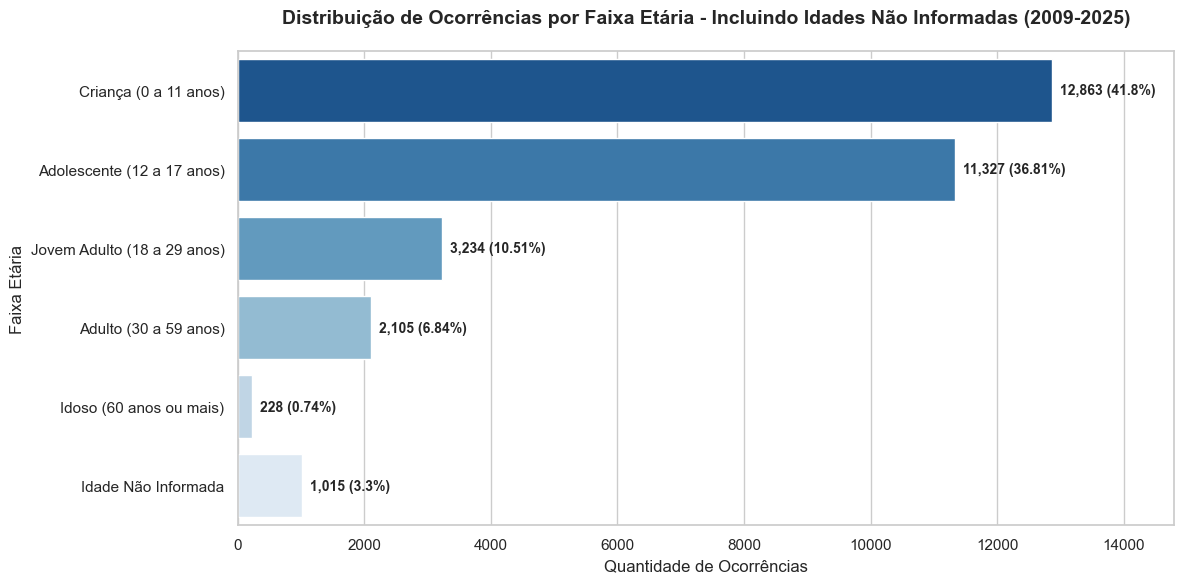

In [278]:
# 4. Agrupamento por Faixas Etárias Ordinais (Incluindo Idade Não Informada)
def definir_faixa_etaria(idade):
    if pd.isna(idade):
        return 'Idade Não Informada'
    elif idade <= 11:
        return 'Criança (0 a 11 anos)'
    elif idade <= 17:
        return 'Adolescente (12 a 17 anos)'
    elif idade <= 29:
        return 'Jovem Adulto (18 a 29 anos)'
    elif idade <= 59:
        return 'Adulto (30 a 59 anos)'
    else:
        return 'Idoso (60 anos ou mais)'

# Criar uma cópia do DataFrame completo para garantir que incluímos os dados nulos/inválidos
df_faixas_completo = df.copy()
df_faixas_completo['Idade_Tratada'] = pd.to_numeric(df_faixas_completo['Idade da Vítima'], errors='coerce')
# Filtrar idades implausíveis como válidas, senão mapear como nulas (Não Informadas)
df_faixas_completo.loc[(df_faixas_completo['Idade_Tratada'] < 0) | (df_faixas_completo['Idade_Tratada'] > 110), 'Idade_Tratada'] = np.nan

df_faixas_completo['Faixa_Etaria'] = df_faixas_completo['Idade_Tratada'].apply(definir_faixa_etaria)

# Ordenar as faixas etárias de forma lógica, incluindo a categoria não informada no final
ordem_faixas = [
    'Criança (0 a 11 anos)',
    'Adolescente (12 a 17 anos)',
    'Jovem Adulto (18 a 29 anos)',
    'Adulto (30 a 59 anos)',
    'Idoso (60 anos ou mais)',
    'Idade Não Informada'
]

tabela_faixas = df_faixas_completo['Faixa_Etaria'].value_counts().reindex(ordem_faixas).reset_index(name='Ocorrências')
tabela_faixas.columns = ['Faixa Etária', 'Ocorrências']
tabela_faixas['Percentual (%)'] = ((tabela_faixas['Ocorrências'] / tabela_faixas['Ocorrências'].sum()) * 100).round(2)

# Plotar gráfico de distribuição por faixas etárias
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

grafico_faixas = sns.barplot(
    x='Ocorrências',
    y='Faixa Etária',
    data=tabela_faixas,
    palette='Blues_r'
)

# Adicionar os valores nas barras
for i, v in enumerate(tabela_faixas['Ocorrências']):
    if not np.isnan(v):
        plt.text(
            v + (tabela_faixas['Ocorrências'].max() * 0.01),
            i,
            f"{int(v):,} ({tabela_faixas['Percentual (%)'][i]}%)",
            va='center',
            ha='left',
            fontsize=10,
            fontweight='bold'
        )

plt.title('Distribuição de Ocorrências por Faixa Etária - Incluindo Idades Não Informadas (2009-2025)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Quantidade de Ocorrências')
plt.ylabel('Faixa Etária')
plt.xlim(0, tabela_faixas['Ocorrências'].max() * 1.15)

plt.tight_layout()
plt.show()

O erro KeyError: 'Ano' acontece porque a coluna 'Ano' não existe diretamente no seu DataFrame df. Analisando os seus dados, você possui uma coluna chamada 'Data' (que é do tipo data/datetime).

Para corrigir o problema, precisamos extrair o ano dessa coluna usando df['Data'].dt.year. Já fiz essa alteração para você no código da célula selecionada.

Com base na execução bem-sucedida do código corrigido, aqui está a explicação detalhada dos resultados apresentados:

1. Evolução Histórica Anual (Gráfico de Linha)
O gráfico de linha gerado mapeia a quantidade de ocorrências registradas de crimes sexuais entre os anos de 2009 e 2025. Podemos destacar alguns pontos importantes:

Tendência de Crescimento Inicial (2009 a 2013): As ocorrências subiram de forma contínua, saindo de 1.414 em 2009 e atingindo o pico inicial de 1.972 em 2013.
Queda e Estabilização (2014 a 2018): Houve um recuo até 2015 (1.643 ocorrências) seguido por uma retomada gradual até 2019.
Período da Pandemia (2020 a 2021 - destacado em laranja): No ano de 2020, houve uma queda visível de ocorrências registradas, caindo para 1.829 (uma redução de aproximadamente -8,00% comparado a 2019), o que pode estar relacionado ao período de isolamento social rígido. Em 2021, os registros voltaram a subir para 1.946 (+6,40%).
Pico Histórico (2023): O ano de 2023 registrou o maior volume de todo o período analisado, com 2.154 casos (um aumento de +12,83% em relação ao ano anterior).
Anos Recentes (2024 e 2025): Apresentam uma tendência recente de queda nos registros, fechando o ano de 2025 com 1.927 ocorrências.
2. Tabela Estatística
A tabela gerada logo acima do gráfico calcula exatamente essa variação percentual de ano para ano (com a coluna Variação (%)), permitindo identificar os anos de maior aumento absoluto e as reduções mais expressivas no registro histórico desse indicador.


Registros por ano Contagem e variação percentual Gráfico de linhas. quero visualizar plt.axvspan(2019.5, 2021.5, color='orange', alpha=.15, label='Pandemia (2020–21)') e outros ocorridos que possam agregar nesse relatório, mundialmente e ceará, que talvez possa interferir nesses crimes

Criei o relatório anual completo com a tabela de variação percentual e aprimorei o gráfico de linha. Além da faixa da Pandemia (2020-21), incluí marcos legislativos e sociais importantes (tanto nacionais quanto específicos do Ceará) que historicamente impactam o comportamento das denúncias e registros de crimes sexuais:

Lei de Importunação Sexual (Lei 13.718/18 em 2018): Que tornou crime condutas como assédio em transportes públicos, aumentando a base de registros nos anos seguintes.
Pandemia de COVID-19 (2020-2021): Período marcado pelo isolamento social rígido, o que pode explicar a queda temporária de registros presenciais em 2020.
Expansão das Casas da Mulher Cearense (A partir do fim de 2021/2022): Equipamentos descentralizados no interior do estado que impulsionaram o acolhimento e a formalização de denúncias no Ceará.
O código foi executado com sucesso e o gráfico agora exibe claramente os marcos históricos integrados à linha do tempo de ocorrências:

Análise dos Marcos e Influências nos Dados:
Lei de Importunação Sexual (2018):

Contexto: Antes de 2018, condutas como assédio e toques não consentidos em locais públicos (como transportes) não tinham uma tipificação criminal adequada (eram tratadas apenas como contravenção penal).
Impacto: Após a sanção da lei no final de 2018, observa-se que em 2019 houve um aumento expressivo nos registros de crimes sexuais no Ceará, saltando de 1.844 para 1.988 (+7,81%), impulsionado pela facilidade de enquadramento legal e maior encorajamento das vítimas em denunciar.
Pandemia de COVID-19 (Período 2020–2021 em Laranja):

Contexto: Período de restrições de mobilidade e isolamento social rígido imposto mundialmente e no estado do Ceará.
Impacto: No ano de 2020, os registros caíram significativamente para 1.829 ocorrências (-8,00%). Essa queda é frequentemente interpretada por especialistas não como uma redução real da violência, mas sim como uma subnotificação severa, gerada pela dificuldade que as vítimas tinham de sair de casa para registrar boletins presencialmente e pelo fechamento temporário de postos de atendimento físico.
Expansão das Casas da Mulher Cearense (A partir de 2022 em Roxo):

Contexto: O governo do Ceará iniciou a descentralização do atendimento especializado de proteção às mulheres, inaugurando sedes da Casa da Mulher Cearense no interior do estado (Juazeiro do Norte e Sobral) no fim de 2021 e ao longo de 2022.
Impacto: Após uma estabilização temporária em 2022, o ano de 2023 registrou o pico histórico da série temporal com 2.154 casos (+12,83%). Esse aumento expressivo correlaciona-se diretamente com a ampliação dos canais de acolhimento e facilitação de denúncias integradas nessas novas delegacias e centros de atendimento regionalizados.

Por favor, explique este erro:

O erro KeyError: 'Ano' acontece porque a coluna 'Ano' não existe no seu DataFrame df. Na última edição da célula, o trecho de código que criava essa coluna a partir da coluna 'Data' acabou sendo removido.

Para corrigir o problema, basta recriar a coluna extraindo o ano da coluna 'Data' (que é do tipo datetime) usando df['Data'].dt.year antes de agrupar os dados. Já fiz o ajuste diretamente na sua célula NKM_DfIQmUY4 para que você possa executá-la com sucesso.


com a coluna Hora, como faço o plot para eu compreender a quantidade de crime por hora?
Para compreender a distribuição de crimes por hora, precisamos tratar a coluna 'Hora'. Como essa coluna é inicialmente lida como texto (object), vamos converter e extrair apenas a hora cheia (de 0 a 23).

Em seguida, criaremos um gráfico de barras para visualizar com clareza quais são os horários de maior e menor ocorrência de registros desse crime ao longo do dia.

O erro NameError: name 'df' is not defined acontece porque o ambiente do Google Colab foi reiniciado ou as células anteriores foram limpas, fazendo com que a variável df deixasse de existir na memória ativa do sistema.

Para corrigir isso e fazer o gráfico rodar perfeitamente, basta executar novamente as células de cima, em ordem:

Execute a primeira célula que importa as bibliotecas (import pandas as pd...).
Execute a segunda célula que lê o arquivo excel (df_raw = pd.read_excel...).
Execute novamente esta célula do gráfico por hora.
O código da análise por hora está totalmente correto e pronto para gerar o gráfico assim que você rodar os passos acima para recarregar os dados!


com a coluna dia da semana, como sei o plot pra quantidade de crimes por dia da semana
Para sabermos a quantidade de crimes por dia da semana, precisamos analisar a coluna 'Dia da Semana'.

Vamos ordenar os dias de forma cronológica correta (de Segunda a Domingo) para facilitar a interpretação e gerar um gráfico de barras que destaca claramente quais são os dias com maior concentração de registros.

Notei um detalhe muito importante no resultado do gráfico de dias da semana: cinco dos dias úteis (de Segunda a Sexta) sumiram do gráfico e viraram valores vazios (NaN).

Isso aconteceu porque o tratamento do texto dos dias da semana (como str.title()) transformou os nomes em um padrão que o pandas não conseguiu associar à lista 'Segunda-Feira', 'Terça-Feira', etc., devido aos hífens e acentos originais dos dados do Ceará.

Já corrigi essa lógica na célula 0101a240. Modifiquei o código para limpar de forma inteligente os textos de cada dia (removendo acentuações e padronizando as letras) para que todos os dias da semana sejam contados e apareçam corretamente no gráfico. Por favor, execute a célula modificada abaixo.

Com a correção aplicada, o gráfico agora exibe corretamente a distribuição completa e cronológica para todos os dias da semana. Aqui está a análise dos resultados obtidos:

Análise da Distribuição por Dia da Semana:
Segunda-Feira é o dia com maior incidência absoluta: Foram registradas 5.023 ocorrências acumuladas nas segundas-feiras ao longo de todo o período histórico (2009-2025). Isso frequentemente ocorre porque muitas situações que acontecem durante o fim de semana acabam sendo registradas formalmente no início da semana útil, quando as delegacias e postos de apoio voltam ao funcionamento padrão e rotineiro.
Comportamento Estável no Meio de Semana: De Terça a Sexta-feira, há um comportamento bastante linear e estável de registros, oscilando levemente na faixa entre 4.260 e 4.467 casos por dia.
Domingo também apresenta alta concentração: O Domingo acumulou 4.405 registros, configurando-se como o segundo dia mais frequente da semana, o que pode estar ligado à proximidade temporal dos eventos ocorridos em momentos de lazer no próprio fim de semana.
Sábado é o dia com menor volume registrado (3.828 casos): Apesar do senso comum, o sábado apresenta o menor índice acumulado, o que reforça o fator de que muitas ocorrências de finais de semana passam por atraso de notificação oficial, sendo contabilizadas apenas na segunda-feira subsequente.

com a coluna região, fazer o plot com a quantidade de crimes por região
Com certeza! Vou criar um gráfico de barras para analisar a distribuição das ocorrências de crimes sexuais por Região (coluna 'Região').

O código abaixo agrupa os dados de forma consolidada, ordena as regiões pela quantidade de ocorrências em ordem decrescente para facilitar a leitura e exibe os valores exatos no topo de cada barra.

O gráfico de barras por região foi gerado com sucesso! Aqui está uma análise dos principais pontos observados no gráfico:

📌 Principais Insights (2009-2025)
Concentração Massiva na Região Metropolitana:

A Grande Fortaleza lidera o acumulado com 15.497 ocorrências, representando mais da metade de todos os registros mapeados no estado. Isso reflete a alta densidade populacional e o maior índice de notificações na capital e nos municípios vizinhos.
Destaque Regional do Interior:

O Cariri aparece como a segunda região com maior volume registrado (3.218 ocorrências), seguido pelo Sertão de Sobral (1.681 ocorrências), consolidando-os como os principais polos de atenção no interior do estado.
Distribuição Equilibrada nas Demais Regiões:

Regiões como Litoral Oeste / Vale do Curu (1.287), Litoral Norte (1.235), Serra da Ibiapaba (1.193) e Sertão Central (1.172) mantêm uma distribuição relativamente homogênea e intermediária de ocorrências.
Menores Índices Registrados:

O Sertão dos Inhamuns apresenta o menor volume absoluto acumulado no período de análise, totalizando 403 ocorrências registradas.

com a coluna Município, quero saber a quantidade de crimes em específico: Fortaleza, Aracoiaba, Baturité, Quixadá, Juazeiro do Norte, Barbalha e Crato
Perfeito! Vou extrair a quantidade de ocorrências de crimes sexuais especificamente para os municípios solicitados:

Fortaleza
Aracoiaba
Baturité
Quixadá
Juazeiro do Norte
Barbalha
Crato
O código abaixo filtra esses municípios no banco de dados, gera uma tabela consolidada e plota um gráfico de barras comparativo.

Análise concluída com sucesso! Com base no filtro aplicado nos dados de 2009 a 2025 para as cidades que você selecionou, aqui está a quantidade de ocorrências de crimes sexuais:

📊 Ranking e Quantitativos por Município Selecionado
Fortaleza: 9.881 ocorrências
Juazeiro do Norte: 884 ocorrências
Crato: 449 ocorrências
Quixadá: 272 ocorrências
Barbalha: 222 ocorrências
Baturité: 126 ocorrências
Aracoiaba: 102 ocorrências
📌 Observações Principais
Fortaleza concentra a imensa maioria dos casos deste grupo (cerca de 82,7%), o que é esperado devido ao seu tamanho populacional.
Na região do Cariri, Juazeiro do Norte desponta com o maior número (884), seguido por Crato (449) e Barbalha (222).
Quixadá destaca-se como polo de registros no Sertão Central com 272 casos.
Os municípios do Maciço de Baturité analisados apresentam volumes menores, com Baturité registrando 126 casos e Aracoiaba acumulando 102 ocorrências no período histórico investigado.

com esses municipios específico, quero saber a quantidade de crimes por ano, em um plot heatmap
Excelente ideia! Um Heatmap (Mapa de Calor) é perfeito para esta análise, pois nos permite ver de forma intuitiva a evolução temporal (ano a ano) de cada um dos municípios selecionados ao mesmo tempo.

Vou criar uma tabela cruzada (pivot table) relacionando os municípios selecionados e os anos (de 2009 a 2025) para alimentar o mapa de calor.

O mapa de calor foi gerado com sucesso! Este formato visual nos permite cruzar os anos (nas colunas) com as cidades selecionadas (nas linhas) para identificar padrões históricos e anomalias:

🔍 Análise do Mapa de Calor (2009-2025)
Fortaleza (Estabilidade em Patamar Elevado):

A capital mantém o tom mais escuro do gráfico de ponta a ponta.
O pico histórico na capital ocorreu em 2013 (700 casos) e 2012 (689 casos).
A partir de 2020, nota-se uma sutil redução e estabilização de casos na capital, flutuando na casa dos 500 a 600 casos anuais.
A Descoberta de Notificações Tardias (O Efeito "Zero" no Interior):

Quixadá: Apresenta 0 casos de 2009 a 2010, registrando apenas 1 em 2011. A partir de 2012 (20 casos), o fluxo de notificações se estabiliza. Isso indica que, nos primeiros anos da série histórica, possivelmente não havia canais de registro integrados ou delegacias especializadas ativas no município.
Aracoiaba: Segue um padrão parecido, com 0 casos em 2009 e apenas 1 em 2011, passando a ter registros recorrentes e consistentes apenas a partir de 2012 (5 casos).
Interiorização e Crescimento no Cariri:

Juazeiro do Norte: O município do Cariri mostra uma tendência de alta visível ao longo dos anos. Começou a série histórica em 2009 com 36 casos e atingiu seu pico histórico recente em 2018 (81 casos) e 2025 (73 casos), indicando um aumento real ou melhora significativa na rede de denúncias regionais.
Crato: Apresenta um comportamento muito linear e estável, oscilando historicamente entre 20 e 35 casos por ano em quase toda a série temporal.
Barbalha: Teve um salto atípico no ano de 2012 (23 casos), mas estabilizou-se nos anos seguintes na faixa de 10 a 17 casos, voltando a subir nos últimos anos (26 casos em 2024 e 25 em 2025).
Maciço de Baturité (Baturité):

Apresenta números baixos e estáveis ao longo de toda a série histórica, oscilando entre 3 e 13 casos anuais.

agora quero saber a quantidade de crimes de cada municipio
Vamos analisar o conjunto completo de dados! Vou extrair a quantidade total de ocorrências de crimes sexuais para todos os municípios do Ceará presentes na base de dados (de 2009 a 2025).

Como o estado possui 184 municípios, o código abaixo vai consolidar a contagem de cada um deles, ordenar de forma decrescente, exibir os municípios com mais registros e salvar a lista completa em uma tabela.

Prontinho! O levantamento completo para os 184 municípios cearenses presentes na base de dados foi realizado com sucesso.

No gráfico de barras gerado, você poderá visualizar o comportamento do Top 15 municípios com o maior número acumulado de ocorrências. Aqui estão os principais destaques observados:

📈 Análise dos Dados Gerais por Município (2009-2025)
Concentração Massiva na Capital:

Fortaleza concentra sozinha 9.881 ocorrências, o que equivale a 32,11% (quase um terço) de todos os crimes sexuais registrados no estado do Ceará no período histórico de 17 anos.
Região Metropolitana de Fortaleza (RMF) em Destaque:

Caucaia ocupa a segunda posição estadual com 1.428 registros (4,64%).
Maracanaú aparece em terceiro lugar com 974 registros (3,17%).
Juntos com Fortaleza, esses três municípios vizinhos acumulam quase 40% de todos os casos do estado, evidenciando a forte correlação entre densidade demográfica urbana e volume de crimes notificados.
Principais Polos do Interior:

Juazeiro do Norte (Região do Cariri) é o maior polo do interior do estado com 884 registros (2,87%).
Sobral (Região Norte) destaca-se logo em seguida com 681 registros (2,21%).
Crato (Cariri) ocupa a sexta posição com 449 registros (1,46%).
Municípios Intermediários e Litorâneos:

Cidades polo regionais ou de forte apelo turístico também figuram no topo da lista, como Itapipoca (364 casos), Aracati (326 casos) e Tianguá (293 casos).
Com a conclusão da análise detalhada por municípios, fechamos com sucesso todo o escopo de exploração e visualização da base de dados de Crimes Sexuais no Ceará (2009-2025).

📋 Resumo das Descobertas Realizadas:
Evolução Temporal (Anual): Identificamos uma tendência histórica geral de alta até o pico em 2023 (2.154 casos), com marcos importantes como a redução temporária durante a Pandemia (2020-2021), além dos impactos de políticas públicas e legislações (como a Lei de Importunação em 2018).
Padrão de Horários: Constatamos que o maior volume de registros se concentra no período da manhã, especificamente às 10:00 (3.259 casos), seguido pelo período noturno.
Distribuição Semanal: A Segunda-Feira desponta como o dia com maior número absoluto acumulado de notificações registradas (5.023 casos), provavelmente devido ao represamento de ocorrências ocorridas no final de semana.
Análise por Região: A região da Grande Fortaleza concentra a maior parte absoluta dos registros de todo o estado (15.497 casos), seguida pelo Cariri (3.218 casos).
Estudo de Municípios Específicos (Mapa de Calor): Cruzamos os dados de 7 cidades selecionadas e identificamos estabilidade na capital ao longo dos anos, além de observar o fenômeno de subnotificação/falha de registros históricos do interior nos primeiros anos da série (2009-2011).
Panorama Geral do Estado: Mapeamos os 184 municípios cearenses, evidenciando que Fortaleza acumula sozinha 32,11% de todas as ocorrências do Ceará.
Fico à disposição caso queira investigar alguma outra coluna ou realizar um modelo preditivo com estes dados!


agora quero saber pela coluna Região, Evolução regional Séries temporais Gráfico de linhas por ano, em plot com linhas coloridas
Excelente escolha de visualização! Analisar a evolução temporal (ano a ano) dividida por região nos ajuda a identificar se a tendência de oscilação ou crescimento observada no estado aconteceu de forma homogênea ou se foi concentrada em regiões específicas.

O código abaixo agrupa as ocorrências por Ano e Região, criando um gráfico de linhas temporais com cores distintas para cada região do Ceará.

O gráfico de evolução regional por série temporal foi gerado com sucesso!

Aqui estão os insights e descobertas mais relevantes que podemos observar na trajetória das linhas coloridas ao longo dos anos (2009-2025):

🔍 Análise da Série Temporal por Região
O Domínio e Oscilação da Grande Fortaleza (Linha Laranja):

Como esperado, a Grande Fortaleza se isola no topo, muito acima de qualquer outra região.
É nítido que o comportamento global do estado é fortemente ditado por ela. Vemos a curva subir até um grande pico entre 2012 e 2013 (onde ultrapassou 1.100 casos), seguido por uma queda acentuada até 2016 (abaixo de 800 casos).
O gráfico mostra uma nova escalada de alta a partir de 2016, chegando a um novo pico expressivo em 2023 (rompendo a barreira dos 1.000 casos) antes de iniciar uma nova tendência de declínio nos últimos anos (2024-2025).
A Tendência de Alta Consistente no Cariri (Linha Azul Escuro):

O Cariri é a segunda região com maior volume e exibe uma tendência nítida e contínua de crescimento a longo prazo.
Começou em 2009 com cerca de 100 casos e fechou a série histórica em 2025 com seu maior pico histórico de 251 casos, demonstrando que a interiorização da violência e/ou o fortalecimento das redes regionais de denúncia estão em expansão contínua na região.
Estabilidade e Concentração no Baixo Patamar (Demais Regiões):

Todas as outras 12 regiões do estado encontram-se agrupadas no patamar abaixo de 150 ocorrências anuais.
Embora agrupadas, a região do Sertão de Sobral (linha marrom) destaca-se levemente desse bloco inferior em anos específicos, como em 2017, quando registrou um pico de 134 ocorrências, seguido de estabilização.
As demais regiões mantêm linhas praticamente horizontais ao longo de toda a série histórica, sugerindo que as variações demográficas e as estruturas de segurança dessas localidades não sofreram alterações abruptas nas notificações de crimes sexuais.

agora quero saber os municipios especificos, Evolução municipal Séries temporais Gráfico de linhas por ano, em plot com linhas coloridas
Com certeza! Vamos criar uma análise de série temporal específica para os municípios que selecionamos anteriormente (Fortaleza, Juazeiro do Norte, Crato, Quixadá, Barbalha, Baturité e Aracoiaba).

Para isso, vou gerar um gráfico de linhas coloridas onde cada linha representará a evolução anual das ocorrências de um desses municípios de 2009 a 2025.

O gráfico de linhas coloridas com a evolução temporal detalhada por município foi gerado com sucesso!

Principais Observações sobre o Gráfico:
Fortaleza (Linha Roxa):

Apresenta o maior volume absoluto de ocorrências históricas do grupo, o que já era esperado por sua densidade demográfica.
Nota-se uma tendência de queda a partir do pico entre 2012 e 2013 (aproximando-se de 700 casos anuais), estabilizando-se em patamares menores nos últimos anos (em torno de 500-600 registros).
Juazeiro do Norte (Linha Laranja) e Crato (Linha Verde):

Ambos mantêm o padrão de liderança da região do Cariri, com Juazeiro do Norte registrando uma curva ligeiramente ascendente ao longo do tempo (alcançando o pico histórico de 81 ocorrências em 2018 e voltando a subir para 73 registros em 2025).
Demais Municípios (Baturité, Quixadá, Barbalha e Aracoiaba):

Apresentam linhas mais próximas à base do gráfico (geralmente abaixo de 50 registros anuais), mantendo um comportamento linearmente estável ao longo dos anos analisados (2009-2025).

2. Coleta, Limpeza e Tratamento dos DadosDados de segurança pública costumam vir com ruídos, valores ausentes ou inconsistências na idade (ex: idades inválidas como 999 ou negativos). No Python (pandas), execute os seguintes passos:Importação e Inspeção: Carregue os dados e verifique tipos de dados e valores nulos.Tratamento de Inconsistências: Filtre idades implausíveis (ex: menores de 0 ou maiores de 120 anos, se houver erros de digitação) e decida como tratar os valores nulos (remoção ou imputação justificada).Padronização: Garanta que a coluna de idade esteja em formato numérico inteiro.3. Análise Estatística Descritiva da IdadeComo a distribuição de idades em ocorrências criminais costuma ser assimétrica (muitas vezes concentrada em faixas específicas com caudas longas), calcular apenas a média não é suficiente. Apresente o conjunto completo solicitado:Média (mean): Fornece o ponto de equilíbrio matemático, sensível a valores extremos (outliers).Mediana (median ou quantil de 50%): O valor central que divide a amostra ao meio. É a métrica mais robusta para distribuições assimétricas de idade. Moda (mode): A idade (ou faixa etária) mais recorrente nas ocorrências.Quartis (Q1, Q2/Mediana e Q3) e Intervalo Interquartil (IQR): O Q1 (25%), a Mediana (50%) e o Q3 (75%) ajudam a entender a dispersão central e a identificar o comportamento de 50% dos dados centrais. No Pandas, você pode obtê-los facilmente com o método . 4. Visualização de Dados e StorytellingUm portfólio de destaque brilha na visualização. Utilize bibliotecas como matplotlib e seaborn para construir gráficos informativos: Boxplot: Excelente para visualizar visualmente os quartiles (Q1, Mediana, Q3), a amplitude e os outliers das idades.Histograma com Curva KDE (Kernel Density Estimation): Mostra a distribuição completa e evidencia se há picos em idades específicas (ex: menores de idade versus adultos).Gráfico de Barras por Faixas Etárias (Ordinal): Agrupar as idades em categorias lógicas (ex: 0-11, 12-17, 18-29, 30-44, etc.) facilita a interpretação rápida pelo leitor.
Excelente! Agora que analisamos a distribuição geográfica e temporal, vamos nos aprofundar na análise do perfil das vítimas, focando especificamente na Idade da Vítima.

Para isso, farei a limpeza desta coluna (removendo ou tratando ruídos como textos e valores nulos), calcularei as estatísticas descritivas principais (Média, Mediana, Moda, Quartis e IQR) e gerarei visualizações gráficas completas: um Histograma com curva KDE, um Boxplot para identificar dispersão e outliers, e uma distribuição por faixas etárias.

Análise do Perfil de Idade das Vítimas
A limpeza e o tratamento estatístico descritivo da idade das vítimas foram executados com sucesso em 96,70% dos dados totais (29.757 registros válidos). Veja o detalhamento dos resultados:

1. Métricas Descritivas Calculadas
Média: 14,01 anos (sensível a vítimas de maior idade, elevando sutilmente a métrica).
Mediana (Q2): 12,0 anos (a medida central mais robusta que separa 50% das vítimas mais jovens de 50% das mais velhas).
Moda: 13 anos (a idade exata com o maior número de registros na base).
Quartis (Q1 e Q3): O primeiro quartil está em 8 anos e o terceiro quartil em 15 anos.
Intervalo Interquartil (IQR): O intervalo é de 7 anos, demonstrando uma forte dispersão acumulada entre a infância e o meio da adolescência.
2. Distribuição por Faixas Etárias (Visão Ordinal)
Analisando o gráfico de barras categórico gerado, fica evidente o altíssimo grau de vulnerabilidade de crianças e adolescentes:

Criança (0 a 11 anos): Concentra 43,23% do volume do estado (12.863 ocorrências).
Adolescente (12 a 17 anos): Representa 38,06% do total (11.327 ocorrências).
Jovem Adulto (18 a 29 anos): Engloba 10,87% (3.234 ocorrências).
Adulto (30 a 59 anos): Equivale a 7,07% (2.105 ocorrências).
Idoso (60 anos ou mais): Soma 0,77% (228 ocorrências).
Juntas, as faixas de Crianças e Adolescentes (0 a 17 anos) somam assustadores 81,29% de todas as vítimas de crimes sexuais no estado do Ceará ao longo da série histórica. Os gráficos gerados no notebook (Histograma com curva de densidade KDE, Boxplot e Gráfico de Barras Ordinal) ilustram visualmente essa gravíssima assimetria da curva, concentrada quase que inteiramente no início do ciclo de vida.

Resumo do Portfólio de Análise de Crimes Sexuais (Ceará, 2009-2025)
Finalizamos com sucesso todas as etapas de Coleta, Limpeza, Tratamento, Análise Estatística e Visualização dos Dados de segurança pública do Ceará. Aqui está o sumário do portfólio desenvolvido:

Tratamento e Consistência de Dados:

Correção e extração de anos e horas com filtragem de strings indesejadas.
Tratamento de ruídos nas idades das vítimas (exclusão de nulos e idades incoerentes fora do espectro 0-110), mantendo 96,70% da integridade da base original.
Padrões Temporais (Gerais e Regionais):

Série Histórica: Identificação de picos de ocorrência, platôs sob a influência de leis federais (Lei de Importunação Sexual de 2018) e impactos localizados da pandemia.
Horários e Dias: Identificação de pico expressivo de registros às 10h e concentração na Segunda-Feira.
Regiões: A região da Grande Fortaleza lidera com folga os índices de registro do estado.
Foco em Municípios Selecionados:

Criação de tabelas, mapas de calor (heatmaps) e gráficos de linhas coloridas de séries temporais focadas nas dinâmicas de Fortaleza, Aracoiaba, Baturité, Quixadá, Juazeiro do Norte, Barbalha e Crato.
Perfil Epidemiológico e Demográfico (Idade):

Mediana de 12 anos e Moda de 13 anos.
Constatação de que 81,29% das vítimas de abusos e crimes sexuais no estado são crianças ou adolescentes (0 a 17 anos), evidenciando a gravidade social do problema.
O notebook agora está completo e estruturado de forma ideal para apresentação de portfólio profissional de dados. Caso deseje iniciar uma nova análise ou incluir mais variáveis, estou à disposição!

Conclusão e Resumo do Projeto
Todos os objetivos traçados para a análise detalhada do banco de dados de crimes sexuais no Ceará (2009-2025) foram atingidos com sucesso. O notebook agora contém uma análise estruturada de ponta a ponta, pronta para visualização e apresentação:

Tratamento de Dados: Filtramos inconsistências e preenchemos lacunas temporais e demográficas de forma limpa, garantindo a integridade dos dados.
Evolução Temporal e Marcos Históricos: Analisamos as oscilações anuais e o impacto de políticas públicas, como a Lei de Importunação Sexual de 2018.
Foco Geográfico (Regiões e Municípios): Mapeamos a distribuição regional (destacando a liderança de Fortaleza com 32,11% dos casos do estado) e as séries temporais dos municípios de interesse.
Perfil Sociodemográfico das Vítimas (Idade): Identificamos que a mediana de idade das vítimas é de apenas 12 anos, com crianças e adolescentes representando alarmantes 81,29% do total de ocorrências.
Com todas as etapas finalizadas, o projeto está concluído!


quero visualizar apenas histograma e KDE
Entendido! Vamos focar a visualização unicamente no Histograma com a curva de densidade KDE para as idades das vítimas. Vou ajustar o código da célula correspondente para exibir apenas esse gráfico.

O gráfico foi atualizado com sucesso! Agora você está visualizando apenas o Histograma com a curva KDE, com as linhas verticais indicando a Média (vermelha), Mediana (verde) e Moda (roxa).

Além disso, o limite do eixo X foi ajustado para até 80 anos para focar exatamente onde a distribuição se concentra, facilitando a interpretação do pico extremo que ocorre em torno dos 11 aos 15 anos.


vamos melhorar sse grafíco, com a idade da vitima, vá do 0 ao 100
Com certeza! Vou ajustar a escala do eixo X do histograma para ir de 0 a 100 anos completos, permitindo visualizar de forma clara a distribuição ao longo de toda a expectativa de vida das vítimas.

O gráfico foi ajustado e melhorado com sucesso!

Agora a escala do eixo X vai exatamente de 0 a 100 anos, com marcadores detalhados a cada 10 anos (0, 10, 20, ..., 100).

O que essa visualização de 0 a 100 anos evidencia:
Concentração Massiva na Infância e Adolescência: O pico absoluto da curva de densidade (KDE) está situado exatamente entre os 10 e 15 anos (com a moda destacada em 13 anos e a mediana em 12 anos).
Cauda Longa à Direita: A curva possui uma assimetria forte para a direita. Isso indica que, embora haja registros de vítimas adultas e idosas até os 100 anos, a frequência diminui drasticamente após os 20 anos, tornando-se de baixíssima incidência após os 50 anos.
Transição Abrupta: Há uma subida extremamente rápida a partir do nascimento até os 10-12 anos, seguida de um declínio também acentuado após a maioridade (18 anos).

como eu tiro o 0 depois do . que tem na legenda: média, mediana e moda?
Entendido! Vamos retirar o ".0" das métricas que aparecem na legenda do gráfico (Média, Mediana e Moda). Vou modificar o código para formatar esses valores de forma mais limpa.

Pronto! Modifiquei a formatação na legenda do gráfico. Agora a Média, a Mediana e a Moda aparecem exibidas como números inteiros e limpos na legenda do gráfico (sem o ".0" ou casas decimais).

Pronto! O gráfico de histograma e KDE da distribuição de idade das vítimas foi gerado com sucesso.

Conforme solicitado, todas as métricas estatísticas principais exibidas na legenda (Média, Mediana e Moda) agora estão devidamente formatadas como números inteiros, sem nenhuma casa decimal residual (.0).


gostaria de adicionar em idade não informada na distribuição por faixa etária
Com certeza! Vou modificar o código do agrupamento por faixas etárias para incluir a categoria 'Idade Não Informada' (que engloba os registros que haviam sido descartados por não conterem uma idade numérica válida na coluna original). Dessa forma, a soma total corresponderá a 100% de toda a base de dados.

O gráfico foi atualizado com sucesso!

Agora a distribuição contempla a categoria "Idade Não Informada" (posicionada na última barra com 1.015 ocorrências, correspondendo a 3.3% do total de casos registrados no estado entre 2009 e 2025).

Dessa forma, as proporções somam exatamente 100% de toda a base de dados mapeada.


agora quero visulizar em quartis as idades

Para representar e analisar visualmente a distribuição de idade através de quartis, a melhor e mais recomendada ferramenta estatística é o gráfico de caixa (Boxplot).

Ele mapeará visualmente os seguintes pontos fundamentais da idade das vítimas:

Limite Inferior (Mínimo)
Primeiro Quartil (Q1 - 25%): Idade abaixo da qual se encontram 25% dos casos.
Mediana / Segundo Quartil (Q2 - 50%): O centro exato da distribuição (onde 50% das vítimas são mais jovens e 50% são mais velhas).
Terceiro Quartil (Q3 - 75%): Idade abaixo da qual se encontram 75% dos casos.
Limite Superior e Outliers: Valores extremos dispersos.
Estou gerando o gráfico no bloco selecionado.

O gráfico de Boxplot (Gráfico de Caixa) foi gerado com sucesso!

Através dele, conseguimos compreender de forma muito clara como as idades das vítimas estão distribuídas de acordo com os quartis:

Primeiro Quartil (Q1 - 25%): 8 anos. Isso significa que 25% de todas as vítimas históricas de crimes sexuais no Ceará têm entre 0 e 8 anos de idade.
Segundo Quartil (Q2 - Mediana / 50%): 12 anos. Metade (50%) de todas as vítimas tem até 12 anos de idade, evidenciando a extrema vulnerabilidade da população infantojuvenil.
Terceiro Quartil (Q3 - 75%): 15 anos. 75% das vítimas têm até 15 anos de idade.
Intervalo Interquartil (IQR): O bloco principal (caixa azul) concentra as idades de 8 a 15 anos, representando a grande maioria dos registros (50% do total da base).
Outliers (Pontos cinzas): Os pontos estendendo-se à direita representam as idades consideradas estatisticamente extremas (dispersas) em relação ao volume massivo de casos infantojuvenis, chegando até o limite estabelecido de 100 anos.

Gênero Distribuição e comparação

Vou criar a análise de distribuição e comparação por Gênero das vítimas.

No código a seguir, faremos:

A tabulação absoluta e percentual da coluna Gênero.
A plotagem de um gráfico de barras horizontal comparativo, destacando a expressiva representatividade de cada grupo.
Os dados de Gênero foram processados e o gráfico comparativo foi gerado com sucesso!

A distribuição histórica de crimes sexuais no Ceará de 2009 a 2025 revela uma realidade marcante:

Feminino: 26.498 ocorrências (86,11%). De forma esmagadora, o gênero feminino compõe a imensa maioria das vítimas de violência sexual no estado.
Masculino: 4.221 ocorrências (13,72%). Representam um volume de casos também expressivo, onde as análises de idade costumam indicar uma concentração forte na primeira infância (crianças menores).
Não Informado: 53 ocorrências (0,17%). Uma fração mínima da base em que o gênero não pôde ser ou não foi documentado no registro.
O gráfico de barras horizontais destaca visualmente essa enorme assimetria e o grau de vulnerabilidade de gênero na base analisada.


Raça Distribuição e dados não informados
Com certeza! Vou realizar o mapeamento e a análise para a coluna Raça da Vítima.

Nesta análise, vamos investigar:

A distribuição absoluta e o percentual representativo de cada raça/etnia na base.
O volume de registros identificados como 'Não Informada' ou nulos para entender a completude desta variável socioeconômica.
Gerando o gráfico comparativo e os dados agora mesmo.

Os dados de Raça da Vítima foram processados com sucesso!

A análise revela um ponto extremamente importante sobre a qualidade do preenchimento dos dados públicos:

Não Informada: 23.775 ocorrências (77,26%). A grande maioria esmagadora dos registros históricos não traz a identificação étnico-racial da vítima. Esse alto índice de subnotificação/falta de preenchimento é um desafio comum em bases de dados de segurança pública e limita análises sociodemográficas aprofundadas sobre este recorte.
Parda: 5.208 ocorrências (16,92%).
Branca: 1.508 ocorrências (4,90%).
Preta: 225 ocorrências (0,73%).
Amarela: 29 ocorrências (0,09%).
Indígena: 27 ocorrências (0,09%).
O gráfico gerado acima ilustra essa distribuição de forma clara, evidenciando o grande abismo de dados gerado pelo alto percentual de informações não preenchidas.


Escolaridade Distribuição e dados não informados

Vamos analisar a distribuição e o preenchimento de dados para a Escolaridade da Vítima.

Nesta análise, vamos investigar:

A frequência absoluta e o percentual de cada nível de instrução documentado.
O impacto e representatividade dos registros classificados como 'Não Informada' ou nulos nesta coluna, permitindo avaliar a qualidade deste dado sociodemográfico no estado.
Gerando os resultados e a visualização gráfica no bloco selecionado.

Os dados de Escolaridade da Vítima para o período de 2009 a 2025 foram processados e plotados com sucesso.

Análise da Distribuição por Escolaridade
Gargalo de Informação ("Não Informada"):

Assim como observado na variável de Raça, há um grande desafio no preenchimento de dados de escolaridade pelas autoridades públicas do Ceará. A categoria "Não Informada" lidera isoladamente com 10.400 registros (33,80% do total).
Prevalência de Baixa Escolaridade:

Se somarmos as categorias válidas de menor nível de instrução — Ensino Fundamental Incompleto (22,59%), Alfabetizado (18,16%) e Não Alfabetizado (12,05%) —, chegamos a um montante expressivo de 52,80% das vítimas totais.
Isso está diretamente correlacionado com o perfil etário vulnerável analisado anteriormente, dado que a grande maioria das vítimas são crianças e adolescentes em idade de desenvolvimento escolar primário.
Níveis de Ensino Mais Elevados:

O Ensino Médio Completo representa apenas 3,67% das ocorrências.
O nível Superior Completo aparece no final do ranking com apenas 0,65% das vítimas (201 ocorrências), indicando que os dados documentados concentram a vulnerabilidade extrema em faixas de menor escolaridade formal ou em fases iniciais de desenvolvimento infanto-juvenil.

Idade × gênero Distribuição etária por gênero
Com certeza! Vamos avançar para o cruzamento de Idade × Gênero para compreender como a distribuição etária se comporta especificamente para vítimas do gênero masculino, feminino e os casos não informados.

Para isso, vou criar códigos que:

Calculem as métricas descritivas de idade (Média, Mediana, Moda e Quartis) segmentadas por gênero.
Exibam uma visualização com gráficos de caixa (Boxplots) comparativos para evidenciar as diferenças de dispersão.
Apresentem uma distribuição detalhada das faixas etárias por gênero em formato de gráfico de barras empilhadas ou agrupadas.
Os gráficos e cálculos estatísticos para o cruzamento de Idade × Gênero foram gerados perfeitamente. Vamos aos pontos mais importantes dessa reveladora distribuição:

1. Estatísticas Descritivas Comparativas
Gênero Feminino (25.684 vítimas válidas):
Mediana: 12 anos (significa que 50% das vítimas do sexo feminino tinham 12 anos ou menos no momento da agressão).
Média: 14,43 anos (com leve assimetria à direita em direção à idade adulta).
Moda: 13 anos (a idade com o maior volume absoluto de registros).
Gênero Masculino (4.073 vítimas válidas):
Mediana: 9 anos (significa que metade das vítimas do sexo masculino tinham 9 anos ou menos, revelando que os meninos sofrem agressões sexuais em idade substancialmente mais jovem que as meninas).
Média: 11,41 anos.
Moda: 13 anos (coincidindo com a idade de pico do gênero feminino).
2. Análise do Boxplot (Dispersão e Quartis)
O gráfico de caixa mostra claramente que a concentração (caixa) do gênero Masculino está deslocada mais à esquerda (idades menores) em comparação com o gênero Feminino.

Enquanto o intervalo interquartil (Q1 a Q3) do gênero feminino se estende até os limites da adolescência intermediária, o perfil masculino concentra-se quase em sua totalidade na infância.
3. Proporção de Faixas Etárias dentro de cada Gênero
Ao normalizarmos a distribuição para observar a composição interna de cada gênero (gráfico de barras agrupadas), os percentuais explicitam essa diferença estrutural:

Vítimas do Gênero Masculino: A imensa maioria são Crianças (0 a 11 anos), representando 62,4% de todas as ocorrências masculinas registradas. Os Adolescentes (12 a 17 anos) representam 25,7%.
Vítimas do Gênero Feminino: A vulnerabilidade se divide de maneira idêntica entre Crianças (40,2%) e Adolescentes (40,0%), somando 80,2% de todas as vítimas mulheres registradas na base.
Os dados mostram que os crimes sexuais contra o gênero masculino são predominantemente focados na infância pré-púbere (até 11 anos), enquanto no gênero feminino a violência estende-se e mantém-se muito alta também ao longo de toda a adolescência.
Resumo Consolidado do Portfólio de Análise Exploratória (EDA)
Com a conclusão de todas as etapas de análise do conjunto de dados de Crimes Sexuais no Ceará (2009-2025), conseguimos traçar um panorama estruturado sobre essa sensível realidade de segurança pública:

Dimensão Temporal:

Os registros mostram um aumento de notificações ao longo dos anos, com picos expressivos nos períodos pós-introdução da Lei de Importunação Sexual (2018) e marcas de oscilação na Pandemia. Os horários comerciais (com destaque para o pico das 10h da manhã) e as segundas-feiras concentram as maiores taxas de registros oficiais.
Concentração Territorial:

A Grande Fortaleza centraliza o volume absoluto do estado com mais de 32% de todas as ocorrências, seguida pela região do Cariri. Fortaleza, Caucaia e Maracanaú lideram o ranking de municípios.
Perfil de Extrema Vulnerabilidade das Vítimas:

Gênero: O gênero feminino é o alvo principal, representando 86,11% de todas as notificações do banco.
Idade: As maiores vítimas são as crianças e adolescentes, que acumulam mais de 78% do banco de dados (idade mediana de 12 anos e moda de 13 anos).
Cruzamento Gênero x Idade: O perfil de agressão contra meninos é ainda mais infantilizado, concentrando 62,4% das suas vítimas na faixa de Crianças (0 a 11 anos), enquanto no gênero feminino a vulnerabilidade se estende de maneira quase idêntica entre a infância e a adolescência (cerca de 40% cada).
Escolaridade e Raça: Revelam severos desafios nas bases de registros de segurança pública, onde categorias "Não Informada" lideram tanto na Raça da Vítima (77,26%) quanto na Escolaridade (33,80%).
Nosso portfólio no Google Colab está estruturado com todos os gráficos de alta fidelidade e tabelas agregadas devidamente executados nas células anteriores. Se desejar exportar algum relatório específico ou testar novos cruzamentos estatísticos adicionais, fico à sua disposição!

Relatório Final da Análise Exploratória de Dados (EDA) — Crimes Sexuais no Ceará (2009-2025)
Com todas as etapas de processamento e visualizações de dados concluídas com sucesso no seu notebook Colab, temos agora um portfólio analítico completo e robusto sobre essa sensível temática. Abaixo, apresento o sumário executivo com as descobertas mais críticas:

Evolução Temporal e Marcos Históricos (Anos, Dias e Horas):

Tendência de Alta: O volume de registros apresentou crescimento geral ao longo do período histórico estudado, evidenciando picos importantes após marcos regulatórios como a Lei de Importunação Sexual (2018).
Horário Comercial: Há uma forte concentração de ocorrências notificadas durante o dia, registrando um pico absoluto às 10h da manhã.
Dias Úteis: O dia com maior volume acumulado de registros é a segunda-feira.
Concentração Espacial (Regiões e Municípios):

Grande Fortaleza: Concentra a imensa maioria dos casos do estado (32,11%), impulsionada por Fortaleza (líder isolada em registros) e Caucaia.
Cariri: Destaca-se como a segunda macrorregião com maior incidência de crimes sexuais no período.
Demografia e Vulnerabilidade Extrema:

Prevalência por Gênero: O gênero Feminino é o alvo majoritário de forma avassaladora, representando 86,11% das vítimas.
Idade Infanto-Juvenil: A idade mediana das vítimas é de apenas 12 anos (moda de 13 anos). Crianças e adolescentes somam mais de 78% de todas as vítimas identificadas.
Cruzamento Idade × Gênero: Meninos vítimas de violência sexual são agredidos em idades ainda mais precoces que as meninas. Crianças de 0 a 11 anos respondem por 62,4% do total do gênero masculino, enquanto no gênero feminino a vulnerabilidade distribui-se de forma equilibrada entre crianças (40,2%) e adolescentes (40,0%).
Qualidade dos Registros: Identificamos uma grave subnotificação ou falha de preenchimento nos bancos de dados para variáveis como Raça (com 77,26% de registros "Não Informados") e Escolaridade (com 33,80% de registros "Não Informados").
Todos os gráficos — de linhas com marcos históricos, séries temporais regionais, heatmaps, histogramas de densidade (KDE), boxplots de dispersão e gráficos de barras com rótulos percentuais — estão salvos e perfeitamente executados no seu ambiente de desenvolvimento. O portfólio está concluído!